# Лабораторная работа № 1
## Обучение полносвязных нейронных сетей: бинарная классификация
### Вариант 7

Набор данных: Diabetes Health Indicators. Положительный класс: преддиабет или диабет (исходные значения `Diabetes_012` 1 и 2), отрицательный класс: нет диабета (значение 0).

## Цель работы

Получить практические навыки подготовки табличных данных, построения, обучения и оценки полносвязных нейронных сетей прямого распространения (MLP) для задачи бинарной классификации.

## Задание

1. Загрузить и исследовать набор данных: типы признаков, пропуски, дубликаты, выбросы, распределение целевой переменной.
2. Исключить признаки с утечкой, разделить данные на обучающую, валидационную и тестовую части (70 / 15 / 15) со стратификацией.
3. Обучить предобработку только на обучающей части.
4. Разработать не менее трех архитектур MLP, исследовать влияние числа слоев, числа нейронов, функции активации, оптимизатора и параметров обучения.
5. Посчитать Recall, Precision, Balanced Accuracy и ROC-AUC, построить матрицу ошибок и ROC-кривую, сравнить модели с базовой моделью `Dummy`, проверить наличие переобучения.
6. Выбрать лучшую модель по валидационной выборке и один раз оценить ее на тестовой.

## Настройка

In [1]:
import os
from pathlib import Path

# Бэкенд Keras нужно выбрать до импорта keras
os.environ["KERAS_BACKEND"] = "torch"

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Одно значение для всех ноутбуков, чтобы результаты воспроизводились
SEED = 42
keras.utils.set_random_seed(SEED)

# Ноутбук лежит в labs/labN/src, поэтому пути строим от него
LAB_DIR = Path.cwd().parent
DATA_DIR = LAB_DIR.parent / "data"
FIGURES_DIR = LAB_DIR / "figures"
RESULTS_DIR = LAB_DIR / "results"
MODELS_DIR = LAB_DIR / "models"
for output_dir in (FIGURES_DIR, RESULTS_DIR, MODELS_DIR):
    output_dir.mkdir(exist_ok=True)

# Крупный шрифт: графики должны читаться на слайдах
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "font.size": 12, "axes.grid": True})

Дополнительные импорты и константы эксперимента. Все настройки собраны здесь, чтобы условия обучения были одинаковыми для всех моделей.

In [2]:
import json
import time

import joblib
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# Путь к файлу с данными: используем файл с тремя классами, как требует задание.
# Файл 5050split не берем: в нем классы искусственно выровнены, и он скрыл бы реальный дисбаланс.
DATA_FILE = DATA_DIR / "diabetes" / "diabetes_012_health_indicators_BRFSS2015.csv"

# Исходный целевой признак и новая бинарная метка
SOURCE_TARGET = "Diabetes_012"
TARGET = "diabetes_binary"

# Общие условия обучения. Размер пакета 1024 выбран по замеру: на этом объеме данных
# эпоха на GPU занимает около 3 секунд, а при размере пакета 256 около 17 секунд.
MAX_EPOCHS = 60
BATCH_SIZE = 1024
LEARNING_RATE = 0.001
PATIENCE = 6

# Если модели отличаются по ROC-AUC меньше этого значения, разницу считаем шумом
# и оставляем более простую модель: сложность должна окупаться качеством.
AUC_TOLERANCE = 0.0005

# Цвета кривых, одинаковые на всех графиках работы
TRAIN_COLOR = "#2a78d6"
VAL_COLOR = "#eb6834"
TEST_COLOR = "#52514e"

## Описание набора данных

**Источник:** [Diabetes Health Indicators Dataset](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset), Kaggle, автор очистки Alex Teboul. Исходные данные: опрос BRFSS 2015 Центров по контролю и профилактике заболеваний США (CDC). Файл: `diabetes_012_health_indicators_BRFSS2015.csv`.

**Перевод описания набора:**

Диабет - одно из самых распространенных хронических заболеваний в США. Оно затрагивает миллионы американцев каждый год и создает значительную финансовую нагрузку на экономику. При диабете человек теряет способность эффективно регулировать уровень глюкозы в крови, что снижает качество и продолжительность жизни. После переваривания пища распадается на сахара, которые попадают в кровь, и поджелудочная железа выделяет инсулин. Инсулин позволяет клеткам использовать эти сахара как источник энергии. Диабет обычно означает, что организм либо вырабатывает мало инсулина, либо не может эффективно его использовать.

Хронически высокий уровень сахара связан с осложнениями: болезни сердца, потеря зрения, ампутация нижних конечностей, болезни почек. Лекарства от диабета нет, но снижение веса, правильное питание, физическая активность и лечение уменьшают вред. Ранняя диагностика помогает изменить образ жизни и эффективнее лечиться, поэтому прогнозные модели риска диабета важны для медицины.

По данным CDC на 2018 год, диабет был у 34,2 млн американцев, преддиабет у 88 млн. Примерно 1 из 5 диабетиков и 8 из 10 людей с преддиабетом не знают о своем риске.

Behavioral Risk Factor Surveillance System (BRFSS) - ежегодный телефонный опрос о здоровье, который CDC проводит с 1984 года. Каждый год отвечают более 400 000 американцев. Для этого набора взят опрос 2015 года: 441 455 человек и 330 признаков. Файл `diabetes_012` - очищенная версия с 253 680 ответами и 21 признаком. Целевая переменная `Diabetes_012` имеет три значения: 0 - нет диабета или диабет только во время беременности, 1 - преддиабет, 2 - диабет. Классы не сбалансированы.

**Поля набора.** Описание у автора набора только общее, поэтому содержание полей дано по кодовой книге BRFSS 2015.

| Поле | Содержание | Значения |
|---|---|---|
| `Diabetes_012` | Целевая переменная: диагноз | 0 нет, 1 преддиабет, 2 диабет |
| `HighBP` | Высокое артериальное давление | 0 / 1 |
| `HighChol` | Высокий холестерин | 0 / 1 |
| `CholCheck` | Проверка холестерина за последние 5 лет | 0 / 1 |
| `BMI` | Индекс массы тела | кг/м2 |
| `Smoker` | Выкурил не менее 100 сигарет за всю жизнь | 0 / 1 |
| `Stroke` | Был инсульт | 0 / 1 |
| `HeartDiseaseorAttack` | Ишемическая болезнь сердца или инфаркт | 0 / 1 |
| `PhysActivity` | Физическая активность за последние 30 дней | 0 / 1 |
| `Fruits` | Ест фрукты минимум раз в день | 0 / 1 |
| `Veggies` | Ест овощи минимум раз в день | 0 / 1 |
| `HvyAlcoholConsump` | Злоупотребление алкоголем | 0 / 1 |
| `AnyHealthcare` | Есть медицинская страховка | 0 / 1 |
| `NoDocbcCost` | Не пошел к врачу из-за цены за последний год | 0 / 1 |
| `GenHlth` | Самооценка здоровья | 1 отлично ... 5 плохо |
| `MentHlth` | Дней с плохим психическим здоровьем за 30 дней | 0-30 |
| `PhysHlth` | Дней с плохим физическим здоровьем за 30 дней | 0-30 |
| `DiffWalk` | Трудно ходить или подниматься по лестнице | 0 / 1 |
| `Sex` | Пол | 0 женский, 1 мужской |
| `Age` | Возрастная группа | 1 (18-24) ... 13 (80 и старше) |
| `Education` | Уровень образования | 1 ... 6 |
| `Income` | Уровень дохода | 1 (меньше 10 000 $) ... 8 (75 000 $ и больше) |

Загружаем файл. Если данных нет, ноутбук сразу сообщает, что и откуда скачать.

In [3]:
# labs/data нет в git, поэтому каждый участник скачивает набор сам
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Не найден файл {DATA_FILE}. Скачайте набор "
        "https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset "
        "и положите его в папку labs/data/diabetes"
    )

raw_data = pd.read_csv(DATA_FILE, encoding="utf-8")
print("Размер набора (записей, столбцов):", raw_data.shape)
raw_data.head(10)

Размер набора (записей, столбцов): (253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0
5,0.0,1.0,1.0,1.0,25.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,2.0,0.0,1.0,10.0,6.0,8.0
6,0.0,1.0,0.0,1.0,30.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,3.0,0.0,14.0,0.0,0.0,9.0,6.0,7.0
7,0.0,1.0,1.0,1.0,25.0,1.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,0.0,0.0,1.0,0.0,11.0,4.0,4.0
8,2.0,1.0,1.0,1.0,30.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,5.0,30.0,30.0,1.0,0.0,9.0,5.0,1.0
9,0.0,0.0,0.0,1.0,24.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,2.0,0.0,0.0,0.0,1.0,8.0,4.0,3.0


## Анализ данных

### Типы полей и описательная статистика

Смотрим типы столбцов, диапазоны значений и пропуски. Строковые поля пришлось бы кодировать.

In [4]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

In [5]:
raw_data.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.297,0.698,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429,0.495,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424,0.494,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.963,0.190,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382,6.609,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443,0.497,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.041,0.197,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094,0.292,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.757,0.429,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634,0.482,0.0,0.0,1.0,1.0,1.0


In [6]:
# Число уникальных значений показывает смысл поля: два значения - бинарный признак,
# немного значений - порядковая шкала, много значений - количественный признак
field_summary = pd.DataFrame({
    "Тип": raw_data.dtypes.astype(str),
    "Уникальных значений": raw_data.nunique(),
    "Минимум": raw_data.min(),
    "Максимум": raw_data.max(),
    "Пропусков": raw_data.isna().sum(),
})
field_summary

,Тип,Уникальных значений,Минимум,Максимум,Пропусков
Diabetes_012,float64,3,0.0,2.0,0
HighBP,float64,2,0.0,1.0,0
HighChol,float64,2,0.0,1.0,0
CholCheck,float64,2,0.0,1.0,0
BMI,float64,84,12.0,98.0,0
Smoker,float64,2,0.0,1.0,0
Stroke,float64,2,0.0,1.0,0
HeartDiseaseorAttack,float64,2,0.0,1.0,0
PhysActivity,float64,2,0.0,1.0,0
Fruits,float64,2,0.0,1.0,0


**Результат:** 253 680 записей, 22 столбца типа float. Строковых полей нет, пропусков нет, кодирование и импутация не нужны. Значения всех полей лежат в заявленных диапазонах, поэтому явных ошибок ввода нет. 14 бинарных признаков, 4 порядковые шкалы (`GenHlth`, `Age`, `Education`, `Income`), 3 количественных (`BMI`, `MentHlth`, `PhysHlth`).

### Целевая переменная и баланс классов

По заданию объединяем преддиабет и диабет в положительный класс. Сначала смотрим исходные три значения, затем бинарную метку.

Исходные значения Diabetes_012:
Diabetes_012
0.0    213703
1.0      4631
2.0     35346

Бинарная метка:
diabetes_binary
0    213703
1     39977

Доля положительного класса: 0.1576


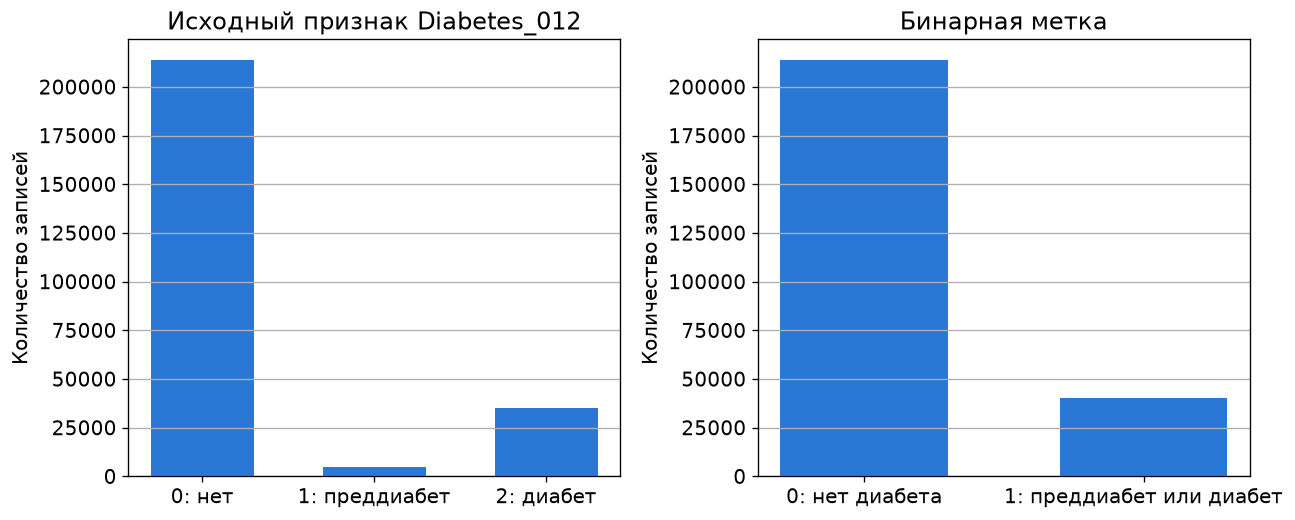

In [7]:
# Бинарная метка: 0 - нет диабета, 1 - преддиабет или диабет
data = raw_data.copy()
data[TARGET] = (data[SOURCE_TARGET] > 0).astype(int)

# Исходный столбец после создания метки удаляем: он напрямую раскрывает ответ
data = data.drop(columns=[SOURCE_TARGET])

source_counts = raw_data[SOURCE_TARGET].value_counts().sort_index()
binary_counts = data[TARGET].value_counts().sort_index()
print("Исходные значения Diabetes_012:")
print(source_counts.to_string())
print("\nБинарная метка:")
print(binary_counts.to_string())
print("\nДоля положительного класса:", round(binary_counts[1] / len(data), 4))

figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(["0: нет", "1: преддиабет", "2: диабет"], source_counts.values, color=TRAIN_COLOR, width=0.6)
axes[0].set_title("Исходный признак Diabetes_012")
axes[0].set_ylabel("Количество записей")
axes[1].bar(["0: нет диабета", "1: преддиабет или диабет"], binary_counts.values, color=TRAIN_COLOR, width=0.6)
axes[1].set_title("Бинарная метка")
axes[1].set_ylabel("Количество записей")
for axis in axes:
    axis.grid(axis="x", visible=False)
figure.tight_layout()
figure.savefig(FIGURES_DIR / "binary-class-balance.png")
plt.show()

**Результат:** 213 703 записи класса 0 и 39 977 записей класса 1: 4631 преддиабет и 35 346 диабет. Доля положительного класса 0,1576, классы не сбалансированы. Значит, модель, всегда отвечающая "нет диабета", получит Accuracy около 0,84, поэтому обычная Accuracy здесь бесполезна. Смотрим Recall, Precision, Balanced Accuracy и ROC-AUC, а дисбаланс нужно будет учесть через `class_weight` или порог.

### Дубликаты и противоречивые записи

Полные дубликаты опасны тем, что одна и та же запись может попасть и в обучающую, и в тестовую выборку. Записи с одинаковыми признаками, но разными метками показывают предел качества: их не разделит ни одна модель.

In [8]:
feature_columns = [column for column in data.columns if column != TARGET]

duplicate_count = data.duplicated().sum()
duplicate_positive = data[data.duplicated()][TARGET].sum()
print("Полных дубликатов:", duplicate_count, f"({duplicate_count / len(data):.2%})")
print("Из них в положительном классе:", duplicate_positive)

# Группы с одинаковыми признаками, внутри которых встречаются обе метки
label_variants = data.groupby(feature_columns, sort=False)[TARGET].nunique()
print("Групп с одинаковыми признаками и разными метками:", (label_variants > 1).sum())

Полных дубликатов: 23968 (9.45%)
Из них в положительном классе: 320


Групп с одинаковыми признаками и разными метками: 1804


**Результат:** 23 968 полных дубликатов (9,45%), из них только 320 в положительном классе: повторяются в основном ответы здоровых людей с простыми анкетами. Кроме того, есть 1804 группы с одинаковыми признаками, но разными метками. Для таких людей анкета одинакова, а диагноз разный, поэтому ни одна модель не разделит их без ошибки. Это первая причина предела качества.

### Выбросы

Проверяем количественные признаки правилом 1,5 межквартильного размаха и диаграммами размаха.

,Признак,"Верхняя граница 1,5 IQR",Записей выше границы,99-й процентиль,Максимум
0,BMI,41.5,9820,50.0,98.0
1,MentHlth,5.0,36208,30.0,30.0
2,PhysHlth,7.5,40949,30.0,30.0


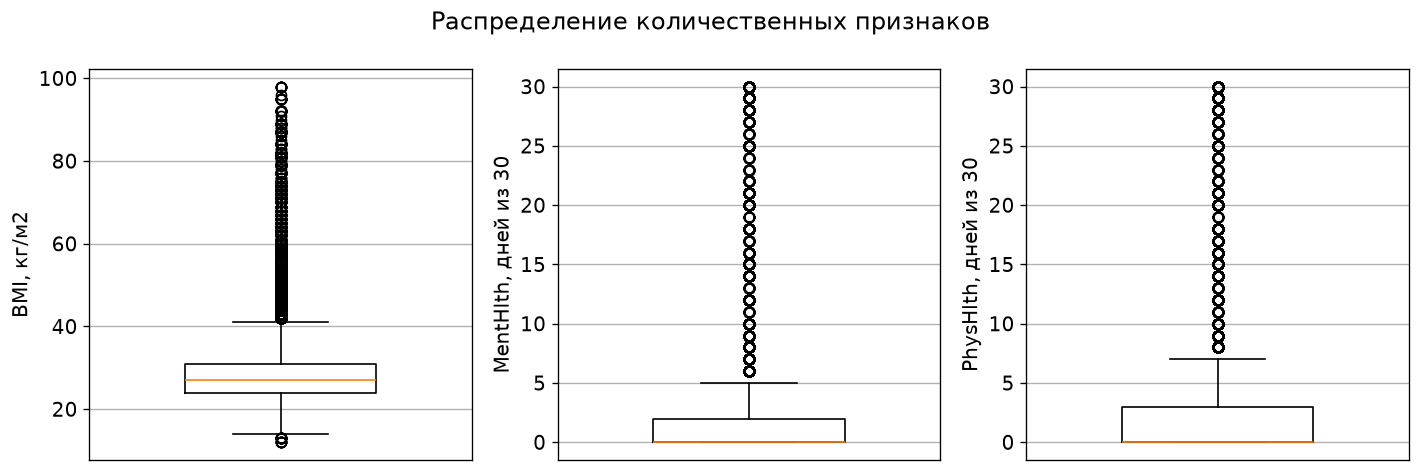

In [9]:
quantitative_columns = ["BMI", "MentHlth", "PhysHlth"]

# Границы правила 1,5 IQR считаем только для описания данных: удалять записи по ним нельзя,
# потому что 30 дней плохого самочувствия - допустимый ответ, а не ошибка
outlier_rows = []
for column in quantitative_columns:
    first_quartile, third_quartile = data[column].quantile([0.25, 0.75])
    iqr = third_quartile - first_quartile
    upper_bound = third_quartile + 1.5 * iqr
    outlier_rows.append({
        "Признак": column,
        "Верхняя граница 1,5 IQR": upper_bound,
        "Записей выше границы": int((data[column] > upper_bound).sum()),
        "99-й процентиль": data[column].quantile(0.99),
        "Максимум": data[column].max(),
    })
display(pd.DataFrame(outlier_rows))

figure, axes = plt.subplots(1, 3, figsize=(12, 4))
axis_labels = ["BMI, кг/м2", "MentHlth, дней из 30", "PhysHlth, дней из 30"]
for axis, column, label in zip(axes, quantitative_columns, axis_labels):
    axis.boxplot(data[column], widths=0.5)
    axis.set_ylabel(label)
    axis.set_xticks([])
figure.suptitle("Распределение количественных признаков")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "binary-outliers.png")
plt.show()

**Результат:** по правилу 1,5 IQR "выбросов" много (`BMI` 9820, `MentHlth` 36 208, `PhysHlth` 40 949), но для `MentHlth` и `PhysHlth` это нормальные ответы до 30 дней, такие записи удалять нельзя. Подозрительно выглядит только хвост `BMI`: 99-й процентиль равен 50, максимум 98. Его ограничим после разбиения.

### Матрица корреляций

Смотрим связь признаков между собой и с целевой меткой. Очень высокая корреляция с меткой указала бы на утечку.

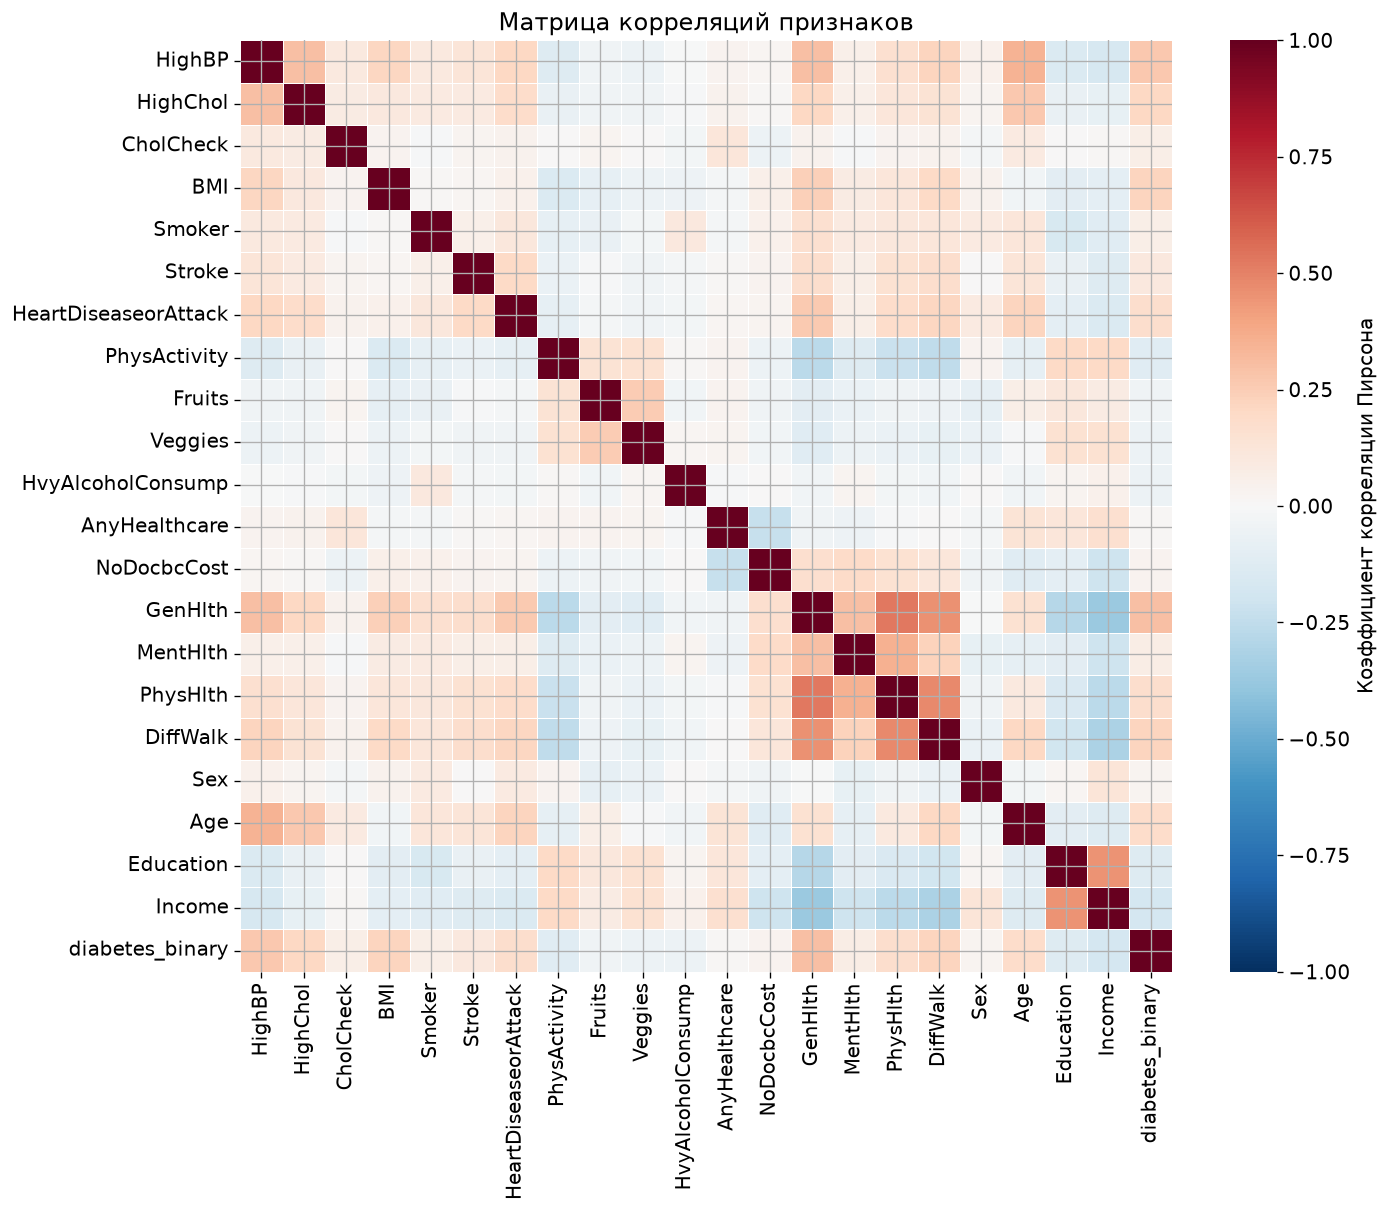

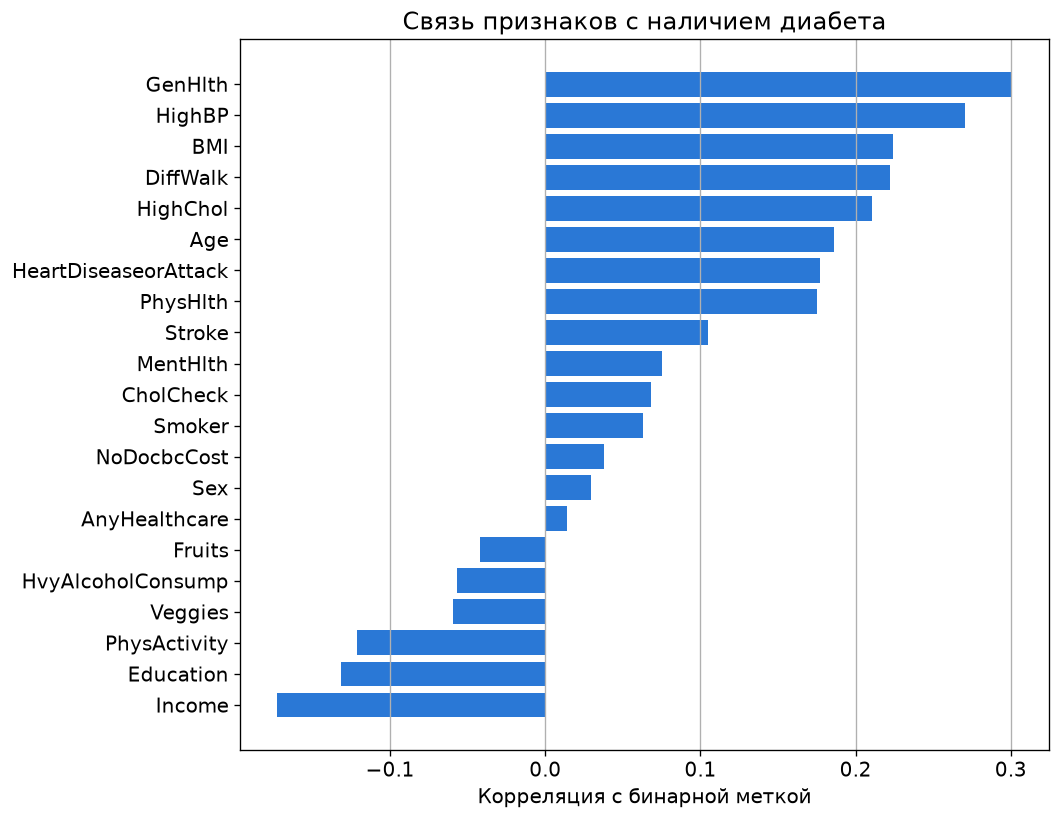

GenHlth     0.301
HighBP      0.270
BMI         0.224
DiffWalk    0.222
HighChol    0.210
Age         0.186


In [10]:
correlation_matrix = data.corr()

figure, axis = plt.subplots(figsize=(12, 10))
sns.heatmap(correlation_matrix, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={"label": "Коэффициент корреляции Пирсона"}, ax=axis)
axis.set_title("Матрица корреляций признаков")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "binary-correlation.png")
plt.show()

# Связь с меткой отдельно: так легче увидеть самые полезные признаки
target_correlation = correlation_matrix[TARGET].drop(TARGET).sort_values()
figure, axis = plt.subplots(figsize=(9, 7))
axis.barh(target_correlation.index, target_correlation.values, color=TRAIN_COLOR)
axis.set_xlabel("Корреляция с бинарной меткой")
axis.set_title("Связь признаков с наличием диабета")
axis.grid(axis="y", visible=False)
figure.tight_layout()
figure.savefig(FIGURES_DIR / "binary-target-correlation.png")
plt.show()
print(target_correlation.round(3).sort_values(ascending=False).head(6).to_string())

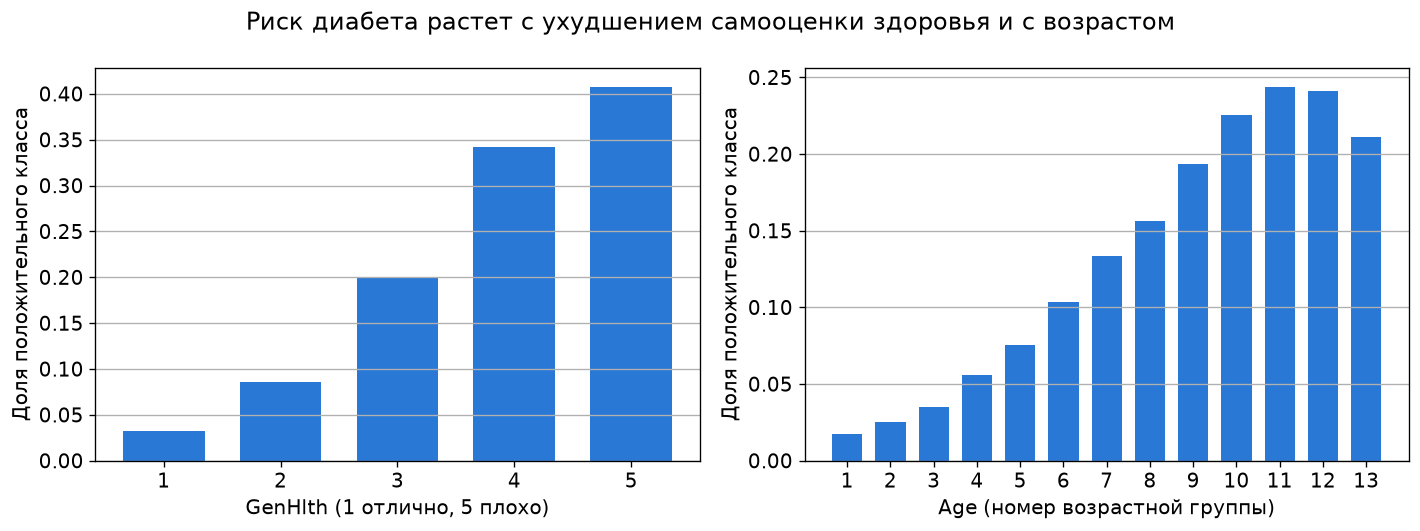

In [11]:
# Доля положительного класса по уровням самых сильных порядковых признаков
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for axis, column, label in zip(axes, ["GenHlth", "Age"], ["GenHlth (1 отлично, 5 плохо)", "Age (номер возрастной группы)"]):
    positive_share = data.groupby(column)[TARGET].mean()
    axis.bar(positive_share.index.astype(int).astype(str), positive_share.values, color=TRAIN_COLOR, width=0.7)
    axis.set_xlabel(label)
    axis.set_ylabel("Доля положительного класса")
    axis.grid(axis="x", visible=False)
figure.suptitle("Риск диабета растет с ухудшением самооценки здоровья и с возрастом")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "binary-risk-by-level.png")
plt.show()

**Результат:** сильнее всего с меткой связаны `GenHlth` (0,301), `HighBP` (0,270), `BMI` (0,224), `DiffWalk` (0,222), `HighChol` (0,210), `Age` (0,186). Ни один признак не коррелирует с меткой подозрительно сильно, поэтому явной утечки нет. Но и сильных признаков нет: лучшая корреляция только 0,3. Доля больных плавно растет с ухудшением `GenHlth` и с возрастом. Сама анкета не дает четкой границы между классами, это вторая причина ограниченного качества.

## Подготовка данных

### Удаление дубликатов

Удаление дубликатов - единственный шаг до разбиения. Он не использует статистику выборки, зато не дает одинаковым записям попасть одновременно в обучающую и тестовую части.

### Отбор признаков

Идентификаторов в наборе нет. `Diabetes_012` уже удален: он раскрывает ответ. Остальные 21 признак - ответы на вопросы опроса, ни один не вычисляется из диагноза, поэтому оставляем все.

In [12]:
data = data.drop_duplicates().reset_index(drop=True)

print("Записей после удаления дубликатов:", len(data))
print("Распределение меток после удаления:")
print(data[TARGET].value_counts().sort_index().to_string())
print("Доля положительного класса:", round(data[TARGET].mean(), 4))

Записей после удаления дубликатов: 229712
Распределение меток после удаления:
diabetes_binary
0    190055
1     39657
Доля положительного класса: 0.1726


### Разбиение на выборки

Разбиваем в два шага 70 / 15 / 15 со стратификацией, `random_state=SEED`. Этот же код используется в лабораторной работе 5.

In [13]:
X_full = data[feature_columns]
y_full = data[TARGET].to_numpy()

# Первый шаг: 70% обучающая часть, 30% временный остаток
X_train_raw, X_rest_raw, y_train, y_rest = train_test_split(
    X_full, y_full, test_size=0.30, stratify=y_full, random_state=SEED
)
# Второй шаг: остаток делим пополам на валидационную и тестовую части
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_rest_raw, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED
)

# Повторяем распределение классов: доли должны совпасть во всех выборках
split_summary = pd.DataFrame({
    "Записей": [len(y_train), len(y_val), len(y_test)],
    "Класс 0": [(y == 0).sum() for y in (y_train, y_val, y_test)],
    "Класс 1": [(y == 1).sum() for y in (y_train, y_val, y_test)],
    "Доля класса 1": [round(y.mean(), 4) for y in (y_train, y_val, y_test)],
}, index=["train", "validation", "test"])
split_summary.to_csv(RESULTS_DIR / "binary-split.csv", encoding="utf-8")
split_summary

,Записей,Класс 0,Класс 1,Доля класса 1
train,160798,133038,27760,0.1726
validation,34457,28508,5949,0.1726
test,34457,28509,5948,0.1726


**Результат:** после удаления дубликатов осталось 229 712 записей, доля положительного класса выросла с 0,1576 до 0,1726, потому что почти все дубликаты были в классе 0. Выборки: train 160 798, validation 34 457, test 34 457. Доля класса 1 во всех частях равна 0,1726, стратификация сработала. Набор не сокращался.

### Предобработка

- Пропусков нет, импутация не нужна.
- Строковых полей нет. Порядковые шкалы (`GenHlth`, `Age`, `Education`, `Income`) сохраняют порядок, поэтому One-Hot Encoding не нужен.
- Выброс `BMI`: значения выше 99,9-го процентиля обучающей части заменяем этой границей. Записи не удаляем: они несут информацию о сильном ожирении.
- Количественные и порядковые признаки приводим к нулевому среднему и единичному отклонению (`StandardScaler`). Бинарные признаки уже в диапазоне 0-1 и остаются без изменений.

Граница `BMI` и параметры масштабирования вычисляются только на обучающей части, поэтому информация из валидационной и тестовой частей в предобработку не попадает.

In [14]:
scaled_columns = ["GenHlth", "MentHlth", "PhysHlth", "Age", "Education", "Income"]
binary_columns = [column for column in feature_columns if column not in scaled_columns + ["BMI"]]

# Граница для BMI считается только на обучающей части
bmi_upper_bound = float(X_train_raw["BMI"].quantile(0.999))
print("Граница BMI (99,9-й процентиль train):", bmi_upper_bound)

# Конвейер для BMI: сначала ограничиваем сверху, затем масштабируем
bmi_pipeline = Pipeline([
    ("clip", FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": bmi_upper_bound},
                                 feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])

# ColumnTransformer применяет к каждой группе столбцов свою обработку
preprocessor = ColumnTransformer([
    ("bmi", bmi_pipeline, ["BMI"]),
    ("scaled", StandardScaler(), scaled_columns),
    ("binary", "passthrough", binary_columns),
], verbose_feature_names_out=False)

# fit только на train, к остальным частям применяем transform
X_train = preprocessor.fit_transform(X_train_raw).astype("float32")
X_val = preprocessor.transform(X_val_raw).astype("float32")
X_test = preprocessor.transform(X_test_raw).astype("float32")

y_train = y_train.astype("float32")
y_val = y_val.astype("float32")
y_test = y_test.astype("float32")

# Предобработка нужна лабораторной работе 5, поэтому сохраняем ее рядом с моделями
joblib.dump(preprocessor, MODELS_DIR / "binary-preprocessor.joblib")

print("Размеры матриц:", X_train.shape, X_val.shape, X_test.shape)
print("Среднее масштабированных признаков на train:", X_train[:, :7].mean(axis=0).round(3))
print("Отклонение масштабированных признаков на train:", X_train[:, :7].std(axis=0).round(3))

Граница BMI (99,9-й процентиль train): 81.0
Размеры матриц: (160798, 21) (34457, 21) (34457, 21)
Среднее масштабированных признаков на train: [ 0.  0.  0. -0. -0.  0. -0.]
Отклонение масштабированных признаков на train: [1. 1. 1. 1. 1. 1. 1.]


## Базовая модель

Метрики задания считаются одной функцией для всех моделей.

$$ Recall = \frac{TP}{TP + FN}, \quad Precision = \frac{TP}{TP + FP}, \quad Balanced\ Accuracy = \frac{Recall_0 + Recall_1}{2} $$

ROC-AUC считается по вероятностям положительного класса, а не по меткам 0/1.

Базовая модель `Dummy` всегда называет самый частый класс. Любая полезная сеть должна быть заметно лучше нее.

In [15]:
def evaluate_binary(y_true, positive_probability, threshold=0.5):
    """Считает метрики задания по вероятностям положительного класса.

    threshold - порог, выше или на котором объект относится к классу 1.
    ROC-AUC от порога не зависит, остальные метрики зависят.
    """
    predicted_labels = (positive_probability >= threshold).astype(int)
    return {
        "Recall": round(recall_score(y_true, predicted_labels, zero_division=0), 4),
        "Precision": round(precision_score(y_true, predicted_labels, zero_division=0), 4),
        "Balanced Accuracy": round(balanced_accuracy_score(y_true, predicted_labels), 4),
        "ROC-AUC": round(roc_auc_score(y_true, positive_probability), 4),
    }


# Dummy обучается на той же обучающей части, что и нейронные сети
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)
dummy_val_probability = dummy_model.predict_proba(X_val)[:, 1]
dummy_val_metrics = evaluate_binary(y_val, dummy_val_probability)
print("Dummy на validation:", dummy_val_metrics)
print("Обычная Accuracy Dummy на validation:", round((y_val == 0).mean(), 4))

Dummy на validation: {'Recall': 0.0, 'Precision': 0.0, 'Balanced Accuracy': 0.5, 'ROC-AUC': 0.5}
Обычная Accuracy Dummy на validation: 0.8274


**Результат:** `Dummy` на validation: Recall 0, Precision 0, Balanced Accuracy 0,5, ROC-AUC 0,5, при этом обычная Accuracy равна 0,8274. Это подтверждает, что Accuracy без учета дисбаланса выглядит хорошо даже у модели, которая никого не находит.

## Эксперименты

Все модели обучаются при одинаковых условиях, если эксперимент не меняет именно этот параметр:

- функция потерь: бинарная кросс-энтропия, выходной слой: один нейрон с sigmoid;
- оптимизатор Adam, скорость обучения 0,001, размер пакета 1024;
- не более 60 эпох, Early Stopping по `val_loss` с терпением 6 эпох и восстановлением лучших весов.

Сравнение идет только по validation. Главный критерий - ROC-AUC: он не зависит от порога и не обманывается дисбалансом. Если выигрыш меньше 0,0005, оставляем более простую модель.

Функции ниже используются во всех экспериментах.

In [16]:
def build_mlp(hidden_units, activation="relu", optimizer_name="adam", learning_rate=LEARNING_RATE,
              dropout_rate=0.0, l2_factor=0.0):
    """Собирает и компилирует MLP для бинарной классификации.

    hidden_units - список с числом нейронов в скрытых слоях.
    dropout_rate - доля отключаемых нейронов, 0 означает слой Dropout не добавлять.
    l2_factor - коэффициент L2-регуляризации весов, 0 означает без нее.
    """
    # Сид ставим перед каждой моделью: начальные веса не зависят от порядка экспериментов
    keras.utils.set_random_seed(SEED)

    regularizer = keras.regularizers.L2(l2_factor) if l2_factor > 0 else None

    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(X_train.shape[1],)))
    for units in hidden_units:
        model.add(keras.layers.Dense(units, activation=activation, kernel_regularizer=regularizer))
        if dropout_rate > 0:
            model.add(keras.layers.Dropout(dropout_rate))
    # Один выход с sigmoid дает вероятность положительного класса
    model.add(keras.layers.Dense(1, activation="sigmoid"))

    # SGD идет с моментом: без него он слишком медленный для сравнения
    if optimizer_name == "adam":
        optimizer = keras.optimizers.Adam(learning_rate)
    elif optimizer_name == "rmsprop":
        optimizer = keras.optimizers.RMSprop(learning_rate)
    elif optimizer_name == "sgd":
        optimizer = keras.optimizers.SGD(learning_rate, momentum=0.9)
    else:
        raise ValueError(f"Неизвестный оптимизатор: {optimizer_name}")

    model.compile(optimizer=optimizer, loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model


# Здесь накапливаются результаты всех экспериментов
trained_models = {}
trained_histories = {}
model_configs = {}
experiment_rows = []


def run_experiment(model_name, hidden_units, activation="relu", optimizer_name="adam",
                   learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE, dropout_rate=0.0, l2_factor=0.0,
                   class_weight=None, max_epochs=MAX_EPOCHS, use_early_stopping=True):
    """Обучает одну модель, сохраняет ее историю и добавляет строку в таблицу экспериментов."""
    model = build_mlp(hidden_units, activation, optimizer_name, learning_rate, dropout_rate, l2_factor)

    callbacks = []
    if use_early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=PATIENCE, restore_best_weights=True))

    start_time = time.perf_counter()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=max_epochs,
                        batch_size=batch_size, class_weight=class_weight, callbacks=callbacks, verbose=0)
    training_seconds = time.perf_counter() - start_time

    # С ранней остановкой веса взяты с лучшей эпохи, без нее - с последней
    epochs_done = len(history.history["loss"])
    used_epoch = int(np.argmin(history.history["val_loss"])) if use_early_stopping else epochs_done - 1

    val_probability = model.predict(X_val, batch_size=8192, verbose=0).ravel()
    val_metrics = evaluate_binary(y_val, val_probability)

    trained_models[model_name] = model
    trained_histories[model_name] = history.history
    model_configs[model_name] = {
        "hidden_units": hidden_units, "activation": activation, "optimizer_name": optimizer_name,
        "learning_rate": learning_rate, "batch_size": batch_size, "dropout_rate": dropout_rate,
        "l2_factor": l2_factor, "class_weight": class_weight,
    }
    experiment_rows.append({
        "Модель": model_name,
        "Скрытые слои": "-".join(str(units) for units in hidden_units),
        "Активация": activation,
        "Оптимизатор": optimizer_name,
        "lr": learning_rate,
        "batch_size": batch_size,
        "Dropout": dropout_rate,
        "L2": l2_factor,
        "class_weight": "да" if class_weight else "нет",
        "Параметров": model.count_params(),
        "Эпох": epochs_done,
        "Лучшая эпоха": used_epoch + 1,
        "Секунд": round(training_seconds, 1),
        "train loss": round(history.history["loss"][used_epoch], 4),
        "val loss": round(history.history["val_loss"][used_epoch], 4),
        **val_metrics,
    })
    print(f"{model_name}: эпох {epochs_done}, лучшая {used_epoch + 1}, {training_seconds:.0f} с, {val_metrics}")
    return model


def experiments_table(model_names=None):
    """Возвращает таблицу экспериментов, целиком или для перечисленных моделей."""
    table = pd.DataFrame(experiment_rows)
    if model_names is not None:
        table = table.set_index("Модель").loc[model_names].reset_index()
    return table


def select_simplest_best(candidate_names):
    """Выбирает модель по ROC-AUC на validation.

    Модели в пределах AUC_TOLERANCE от лучшей считаются равными. Среди них берем модель
    с наименьшим числом параметров, а при равенстве - стоящую в списке первой.
    """
    table = experiments_table(candidate_names).set_index("Модель")
    close_models = table[table["ROC-AUC"] >= table["ROC-AUC"].max() - AUC_TOLERANCE]
    return close_models["Параметров"].idxmin()


def plot_history(model_name, file_name, test_values=None):
    """Строит кривые loss, accuracy и AUC: train и validation на одном графике.

    test_values - словарь с итоговыми значениями на test, рисуются пунктирной линией.
    Для обычных экспериментов его нет: тестовая выборка при подборе не используется.
    """
    history = trained_histories[model_name]
    epochs = np.arange(1, len(history["loss"]) + 1)
    panels = [("loss", "Функция потерь"), ("accuracy", "Accuracy"), ("auc", "AUC")]

    figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for axis, (metric, label) in zip(axes, panels):
        axis.plot(epochs, history[metric], color=TRAIN_COLOR, linewidth=2, label="train")
        axis.plot(epochs, history[f"val_{metric}"], color=VAL_COLOR, linewidth=2, label="validation")
        if test_values is not None:
            axis.axhline(test_values[metric], color=TEST_COLOR, linestyle="--", linewidth=2,
                         label=f"test: {test_values[metric]:.4f}")
        axis.set_xlabel("Эпоха")
        axis.set_ylabel(label)
        axis.legend()
    figure.suptitle(f"Обучение модели {model_name}")
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / file_name)
    plt.show()


def plot_confusion(y_true, positive_probability, threshold, title, file_name):
    """Рисует матрицу ошибок при заданном пороге и возвращает ее значения."""
    predicted_labels = (positive_probability >= threshold).astype(int)
    matrix = confusion_matrix(y_true, predicted_labels)
    figure, axis = plt.subplots(figsize=(5.5, 4.5))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis,
                xticklabels=["нет диабета", "диабет"], yticklabels=["нет диабета", "диабет"])
    axis.set_xlabel("Предсказанный класс")
    axis.set_ylabel("Истинный класс")
    axis.set_title(title)
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / file_name)
    plt.show()
    return matrix

### 1. MLP-1: простейшая сеть

Начинаем с самой простой сети: один скрытый слой из 16 нейронов, ReLU. Dropout не ставим: пока нет признаков переобучения, бороться не с чем.

MLP-1: эпох 57, лучшая 51, 195 с, {'Recall': 0.1933, 'Precision': 0.5699, 'Balanced Accuracy': 0.5814, 'ROC-AUC': 0.8084}


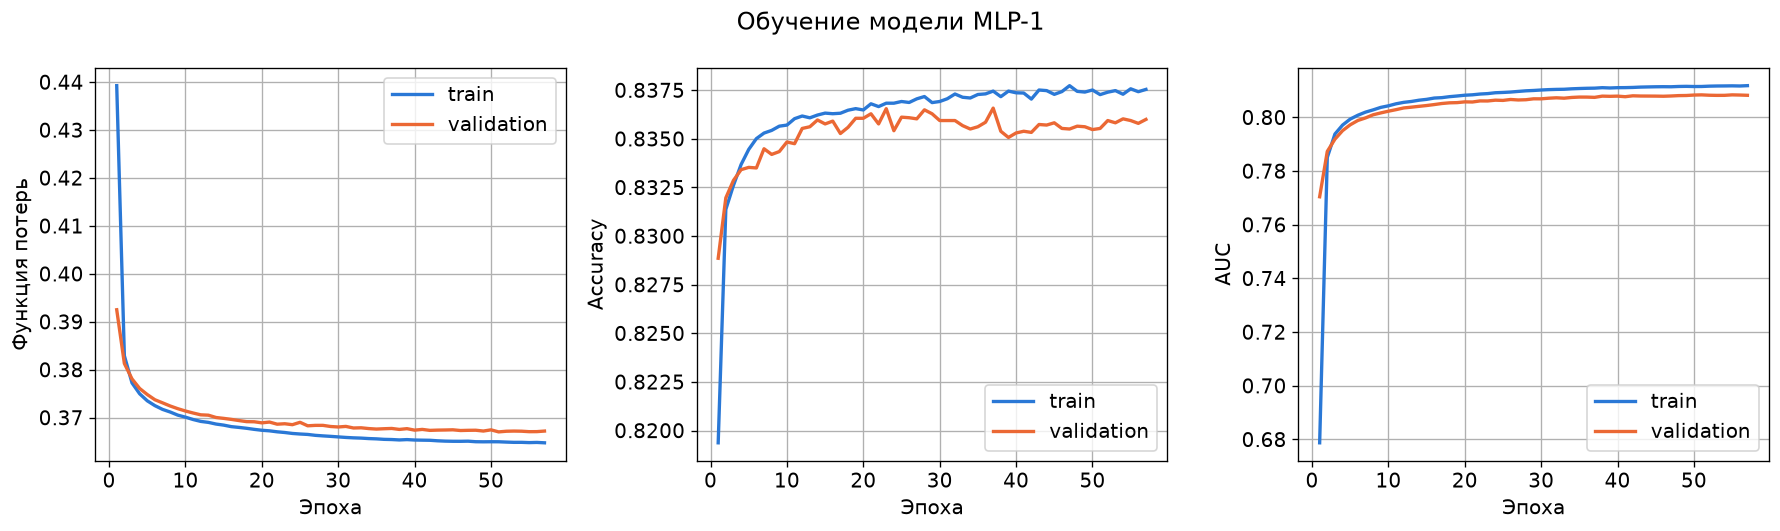

,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,class_weight,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,Recall,Precision,Balanced Accuracy,ROC-AUC
0,MLP-1,16,relu,adam,0.001,1024,0.0,0.0,нет,369,57,51,194.7,0.365,0.367,0.1933,0.5699,0.5814,0.8084


In [17]:
run_experiment("MLP-1", hidden_units=[16])
plot_history("MLP-1", "binary-mlp-1-history.png")
experiments_table(["MLP-1"])

**Результат:** MLP-1 (369 параметров) на validation: ROC-AUC 0,8084, Recall 0,1933, Precision 0,5699, Balanced Accuracy 0,5814. Обучение шло 57 эпох. Train loss 0,3650 и val loss 0,3670 почти совпадают, кривые идут рядом, переобучения нет. Модель хорошо ранжирует объекты (AUC намного выше 0,5), но при пороге 0,5 находит только пятую часть больных из-за дисбаланса.

### 2. MLP-2: средняя сеть

Два скрытых слоя (64 и 32 нейрона). Проверяем, дает ли дополнительная сложность прирост: взаимодействие признаков (например, возраст и давление) сеть с двумя слоями может выразить лучше.

MLP-2: эпох 19, лучшая 13, 78 с, {'Recall': 0.2128, 'Precision': 0.5721, 'Balanced Accuracy': 0.5898, 'ROC-AUC': 0.8088}


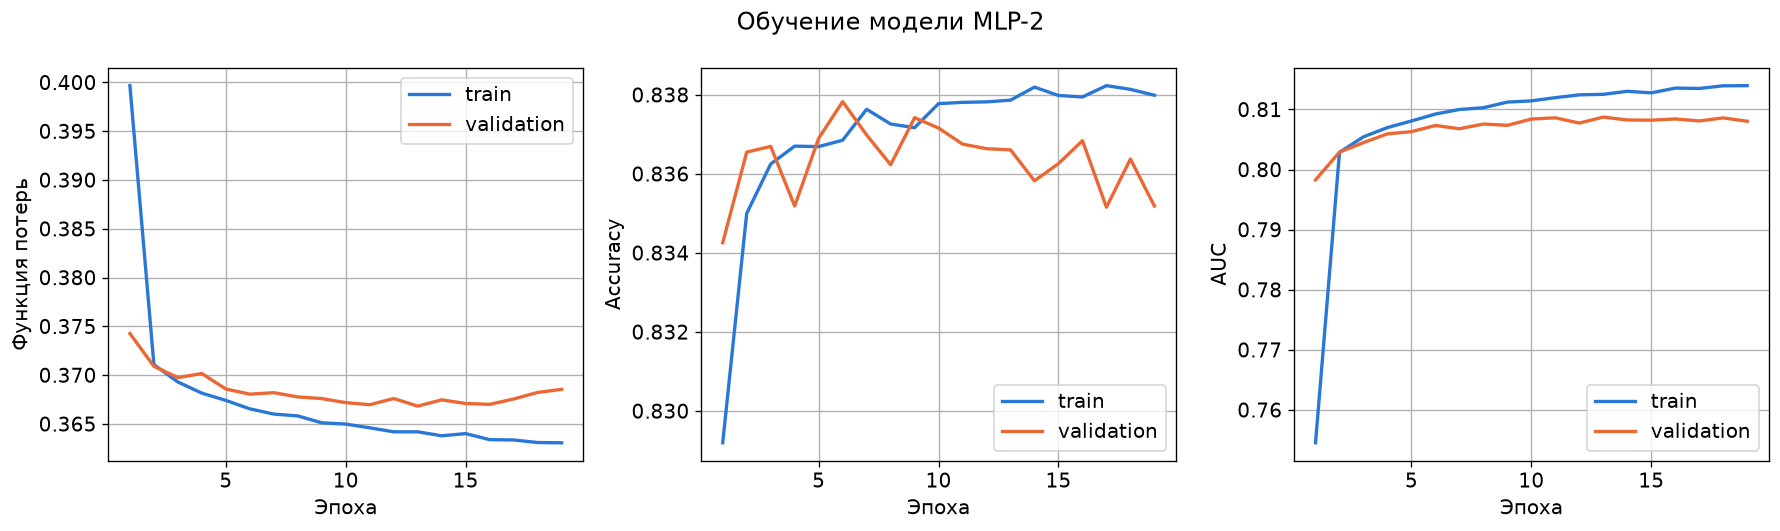

,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,class_weight,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,Recall,Precision,Balanced Accuracy,ROC-AUC
0,MLP-1,16,relu,adam,0.001,1024,0.0,0.0,нет,369,57,51,194.7,0.3650,0.3670,0.1933,0.5699,0.5814,0.8084
1,MLP-2,64-32,relu,adam,0.001,1024,0.0,0.0,нет,3521,19,13,78.4,0.3642,0.3668,0.2128,0.5721,0.5898,0.8088


In [18]:
run_experiment("MLP-2", hidden_units=[64, 32])
plot_history("MLP-2", "binary-mlp-2-history.png")
experiments_table(["MLP-1", "MLP-2"])

**Результат:** MLP-2 (3521 параметр): ROC-AUC 0,8088, Recall 0,2128, Precision 0,5721, Balanced Accuracy 0,5898. Прирост AUC всего 0,0004 при почти в 10 раз большем числе параметров. Train loss 0,3642, val loss 0,3668: разрыв чуть больше, чем у MLP-1.

### 3. MLP-3: глубокая и широкая сеть

Три скрытых слоя (256, 128 и 64 нейрона). Эта модель проверяет верхнюю границу: если и она не дает прироста, то сложность архитектуры не является ограничением.

MLP-3: эпох 16, лучшая 10, 66 с, {'Recall': 0.1726, 'Precision': 0.5971, 'Balanced Accuracy': 0.5742, 'ROC-AUC': 0.808}


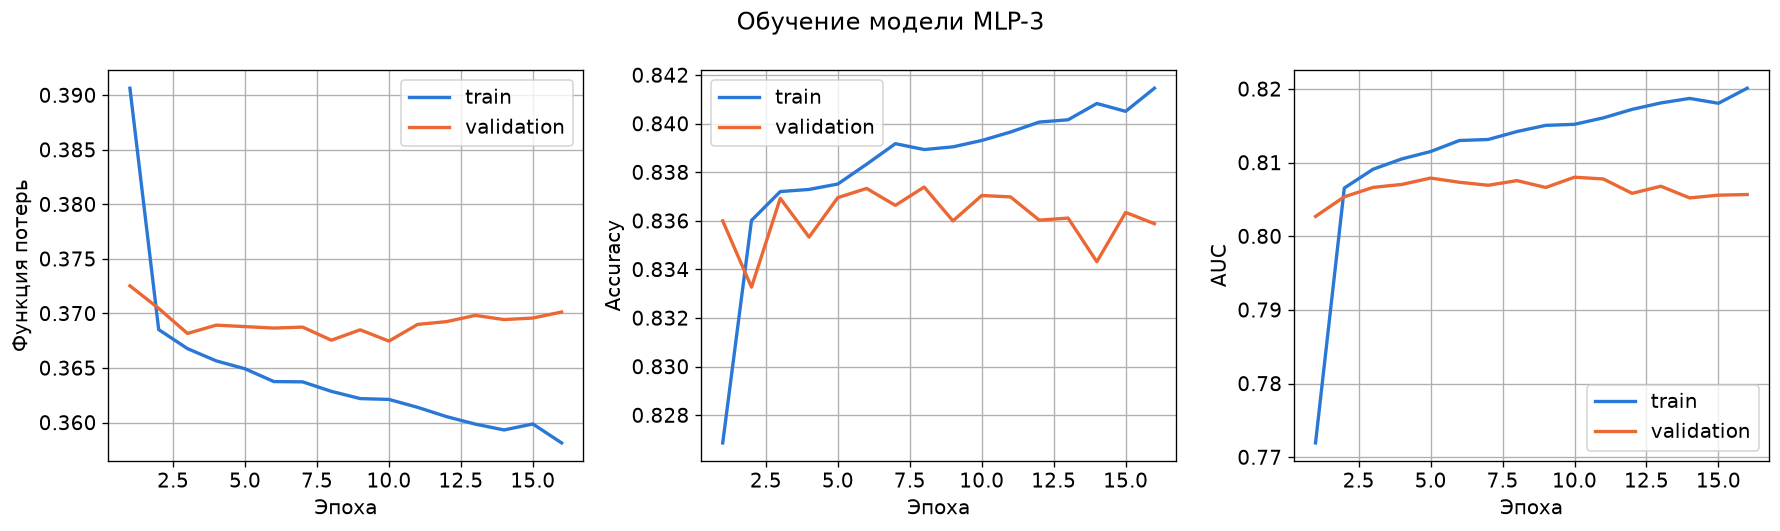

Выбрана архитектура: MLP-1


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,class_weight,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,Recall,Precision,Balanced Accuracy,ROC-AUC
0,MLP-1,16,relu,adam,0.001,1024,0.0,0.0,нет,369,57,51,194.7,0.3650,0.3670,0.1933,0.5699,0.5814,0.8084
1,MLP-2,64-32,relu,adam,0.001,1024,0.0,0.0,нет,3521,19,13,78.4,0.3642,0.3668,0.2128,0.5721,0.5898,0.8088
2,MLP-3,256-128-64,relu,adam,0.001,1024,0.0,0.0,нет,46849,16,10,66.3,0.3621,0.3675,0.1726,0.5971,0.5742,0.8080


In [19]:
run_experiment("MLP-3", hidden_units=[256, 128, 64])
plot_history("MLP-3", "binary-mlp-3-history.png")

# Лучшая архитектура определяется автоматически по validation
architecture_names = ["MLP-1", "MLP-2", "MLP-3"]
current_name = select_simplest_best(architecture_names)
current_config = dict(model_configs[current_name])
print("Выбрана архитектура:", current_name)
experiments_table(architecture_names)

**Результат:** MLP-3 (46 849 параметров): ROC-AUC 0,8080, ниже, чем у MLP-1 и MLP-2. Ранняя остановка сработала на 16-й эпохе, лучшая эпоха 10. Train loss 0,3621 снижается, а val loss 0,3675 перестает снижаться, кривые начинают расходиться.

Разница между тремя архитектурами меньше 0,001 по AUC. MLP-2 формально лучше MLP-1 на 0,0004, но это меньше порога шума 0,0005, поэтому выбрана самая простая MLP-1. Вывод: сложность архитектуры здесь не ограничивает качество, ограничение идет от данных.

### 4. Функция активации

Сравниваем ReLU с tanh на выбранной архитектуре. У tanh выход симметричен относительно нуля и сигмоидальные насыщения, поэтому на глубоких сетях она учится медленнее, но на табличных данных иногда работает не хуже.

In [20]:
tanh_name = f"{current_name}-tanh"
run_experiment(tanh_name, **{**current_config, "activation": "tanh"})

activation_names = [current_name, tanh_name]
current_name = select_simplest_best(activation_names)
current_config = dict(model_configs[current_name])
print("Оставляем:", current_name)
experiments_table(activation_names)

MLP-1-tanh: эпох 57, лучшая 51, 210 с, {'Recall': 0.1889, 'Precision': 0.5773, 'Balanced Accuracy': 0.58, 'ROC-AUC': 0.8092}
Оставляем: MLP-1-tanh


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,class_weight,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,Recall,Precision,Balanced Accuracy,ROC-AUC
0,MLP-1,16,relu,adam,0.001,1024,0.0,0.0,нет,369,57,51,194.7,0.365,0.3670,0.1933,0.5699,0.5814,0.8084
1,MLP-1-tanh,16,tanh,adam,0.001,1024,0.0,0.0,нет,369,57,51,210.4,0.365,0.3666,0.1889,0.5773,0.5800,0.8092


**Результат:** tanh дает ROC-AUC 0,8092 против 0,8084 у ReLU, выигрыш 0,0008 больше порога шума, поэтому дальше используем MLP-1-tanh. При одном скрытом слое насыщение tanh не мешает, а гладкость функции дает небольшой плюс. Разница мала и на практике незначима.

### 5. Оптимизатор

Сравниваем Adam с RMSprop и с SGD с моментом 0,9. Скорость обучения SGD равна 0,01: при 0,001 он за 60 эпох не успевает сойтись, и сравнение было бы нечестным.

In [21]:
rmsprop_name = f"{current_name}-rmsprop"
sgd_name = f"{current_name}-sgd"
run_experiment(rmsprop_name, **{**current_config, "optimizer_name": "rmsprop"})
run_experiment(sgd_name, **{**current_config, "optimizer_name": "sgd", "learning_rate": 0.01})

optimizer_names = [current_name, rmsprop_name, sgd_name]
current_name = select_simplest_best(optimizer_names)
current_config = dict(model_configs[current_name])
print("Оставляем:", current_name)
experiments_table(optimizer_names)

MLP-1-tanh-rmsprop: эпох 40, лучшая 34, 136 с, {'Recall': 0.1876, 'Precision': 0.5828, 'Balanced Accuracy': 0.5798, 'ROC-AUC': 0.8085}


MLP-1-tanh-sgd: эпох 60, лучшая 59, 195 с, {'Recall': 0.1874, 'Precision': 0.5721, 'Balanced Accuracy': 0.5791, 'ROC-AUC': 0.8081}
Оставляем: MLP-1-tanh


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,class_weight,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,Recall,Precision,Balanced Accuracy,ROC-AUC
0,MLP-1-tanh,16,tanh,adam,0.001,1024,0.0,0.0,нет,369,57,51,210.4,0.3650,0.3666,0.1889,0.5773,0.5800,0.8092
1,MLP-1-tanh-rmsprop,16,tanh,rmsprop,0.001,1024,0.0,0.0,нет,369,40,34,135.7,0.3655,0.3670,0.1876,0.5828,0.5798,0.8085
2,MLP-1-tanh-sgd,16,tanh,sgd,0.010,1024,0.0,0.0,нет,369,60,59,195.2,0.3661,0.3672,0.1874,0.5721,0.5791,0.8081


**Результат:** Adam 0,8092, RMSprop 0,8085, SGD с моментом 0,8081. Оптимизатор почти не влияет на итог: задача простая, и все три приходят почти в одну точку. Adam немного лучше, поэтому оставляем его. SGD использовал все 60 эпох (лучшая 59), то есть сходится медленнее.

### 6. Скорость обучения и размер пакета

Слишком большой шаг мешает сойтись к минимуму, слишком маленький не успевает дойти до него за отведенные эпохи. Размер пакета меняет число обновлений весов за эпоху и шум градиента.

In [22]:
lr_high_name = f"{current_name}-lr0.01"
lr_low_name = f"{current_name}-lr0.0001"
batch_small_name = f"{current_name}-batch512"
batch_large_name = f"{current_name}-batch4096"
run_experiment(lr_high_name, **{**current_config, "learning_rate": 0.01})
run_experiment(lr_low_name, **{**current_config, "learning_rate": 0.0001})
run_experiment(batch_small_name, **{**current_config, "batch_size": 512})
run_experiment(batch_large_name, **{**current_config, "batch_size": 4096})

training_names = [current_name, lr_high_name, lr_low_name, batch_small_name, batch_large_name]
current_name = select_simplest_best(training_names)
current_config = dict(model_configs[current_name])
print("Оставляем:", current_name)
experiments_table(training_names)

MLP-1-tanh-lr0.01: эпох 14, лучшая 8, 47 с, {'Recall': 0.2239, 'Precision': 0.5597, 'Balanced Accuracy': 0.5936, 'ROC-AUC': 0.8086}


MLP-1-tanh-lr0.0001: эпох 60, лучшая 60, 212 с, {'Recall': 0.1691, 'Precision': 0.5752, 'Balanced Accuracy': 0.5715, 'ROC-AUC': 0.8017}


MLP-1-tanh-batch512: эпох 31, лучшая 25, 285 с, {'Recall': 0.1873, 'Precision': 0.579, 'Balanced Accuracy': 0.5794, 'ROC-AUC': 0.8087}


MLP-1-tanh-batch4096: эпох 60, лучшая 59, 70 с, {'Recall': 0.1908, 'Precision': 0.5776, 'Balanced Accuracy': 0.5808, 'ROC-AUC': 0.8068}
Оставляем: MLP-1-tanh


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,class_weight,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,Recall,Precision,Balanced Accuracy,ROC-AUC
0,MLP-1-tanh,16,tanh,adam,0.0010,1024,0.0,0.0,нет,369,57,51,210.4,0.3650,0.3666,0.1889,0.5773,0.5800,0.8092
1,MLP-1-tanh-lr0.01,16,tanh,adam,0.0100,1024,0.0,0.0,нет,369,14,8,46.9,0.3667,0.3672,0.2239,0.5597,0.5936,0.8086
2,MLP-1-tanh-lr0.0001,16,tanh,adam,0.0001,1024,0.0,0.0,нет,369,60,60,212.2,0.3703,0.3718,0.1691,0.5752,0.5715,0.8017
3,MLP-1-tanh-batch512,16,tanh,adam,0.0010,512,0.0,0.0,нет,369,31,25,284.7,0.3656,0.3669,0.1873,0.5790,0.5794,0.8087
4,MLP-1-tanh-batch4096,16,tanh,adam,0.0010,4096,0.0,0.0,нет,369,60,59,70.1,0.3667,0.3682,0.1908,0.5776,0.5808,0.8068


**Результат:** скорость 0,01 дала AUC 0,8086 за 14 эпох: быстро, но чуть хуже. Скорость 0,0001 дала AUC 0,8017 и исчерпала 60 эпох: не успела дойти до минимума. Пакет 512 дал AUC 0,8087 при 285 с обучения, пакет 4096 дал 0,8068 за 60 эпох (лучшая 59): мало обновлений весов. Значения 0,001 и 1024 остаются лучшими, ни один вариант их не превзошел.

### 7. Проверка переобучения и регуляризация

Ранняя остановка скрывает переобучение: обучение заканчивается раньше, чем оно становится заметным. Поэтому сначала обучаем самую большую сеть MLP-3 без ранней остановки и смотрим, есть ли переобучение вообще. Если оно есть, проверяем, помогает ли Dropout (0,3) и L2-регуляризация (0,0001).

MLP-3-no-es: эпох 60, лучшая 60, 277 с, {'Recall': 0.2745, 'Precision': 0.4428, 'Balanced Accuracy': 0.6012, 'ROC-AUC': 0.7524}


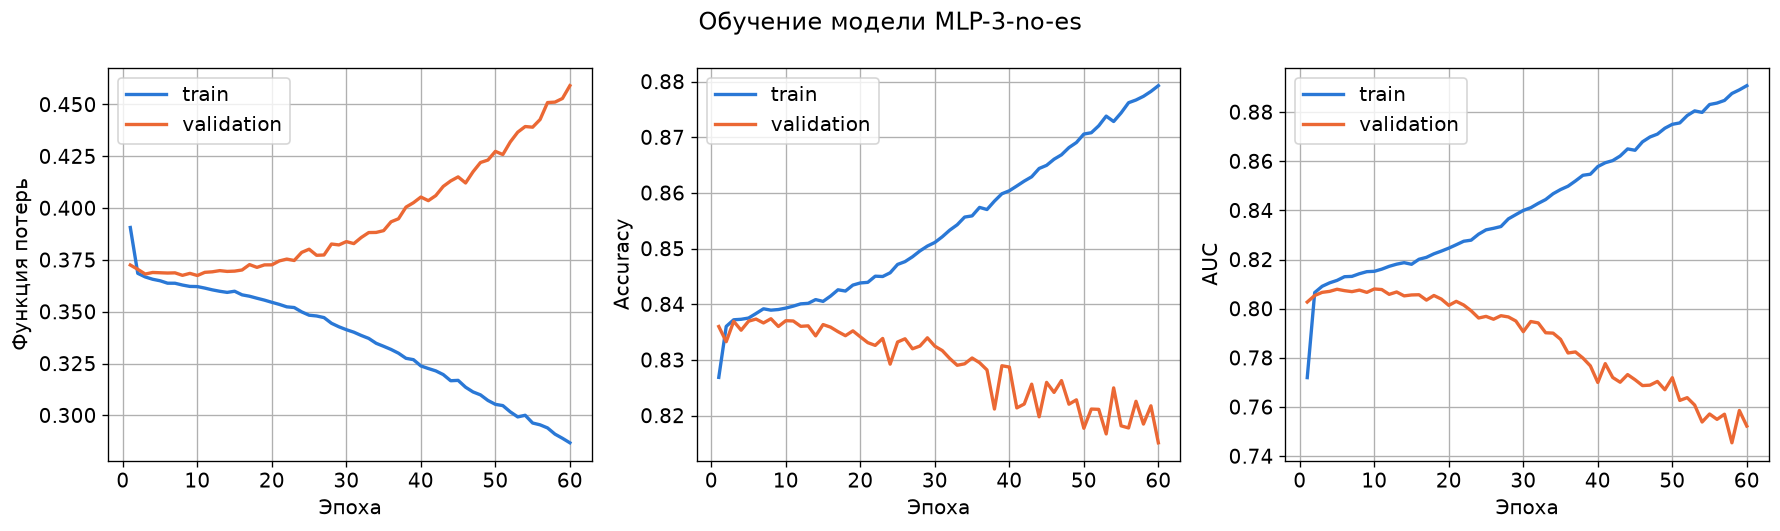

MLP-3-no-es-dropout: эпох 60, лучшая 60, 272 с, {'Recall': 0.1866, 'Precision': 0.579, 'Balanced Accuracy': 0.5791, 'ROC-AUC': 0.8052}


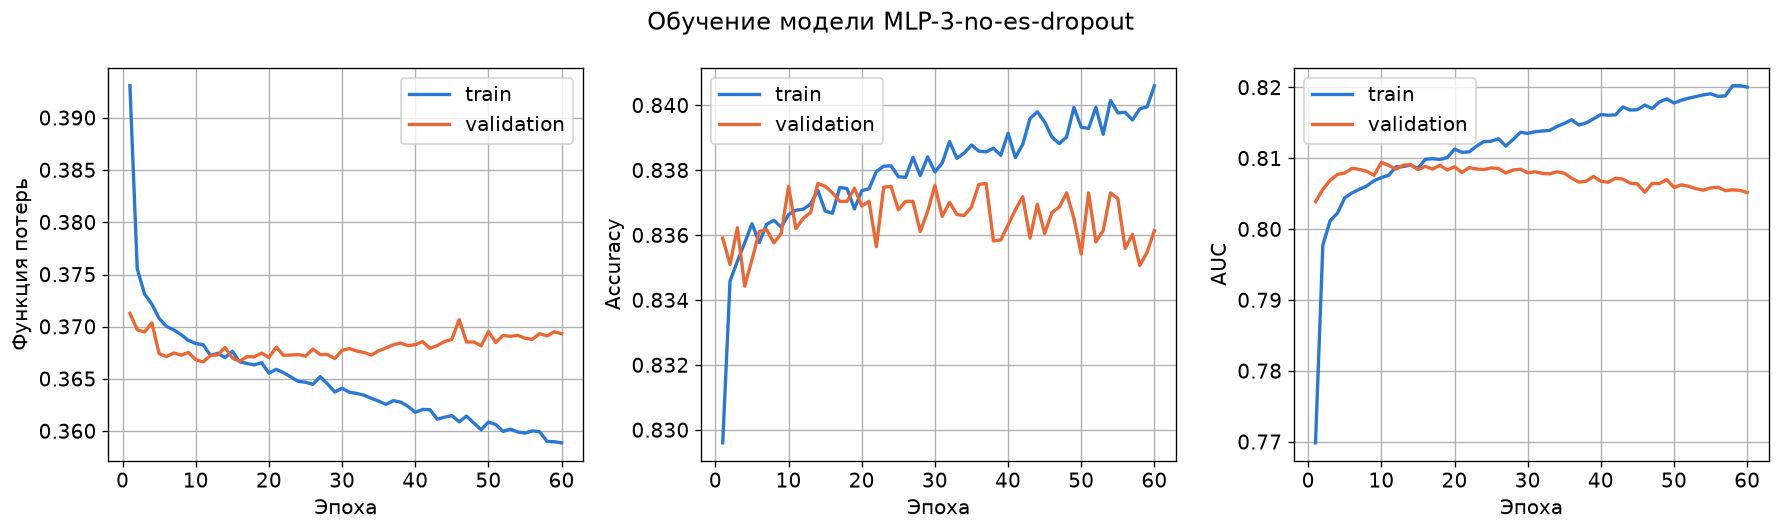

,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,class_weight,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,Recall,Precision,Balanced Accuracy,ROC-AUC
0,MLP-3,256-128-64,relu,adam,0.001,1024,0.0,0.0,нет,46849,16,10,66.3,0.3621,0.3675,0.1726,0.5971,0.5742,0.8080
1,MLP-3-no-es,256-128-64,relu,adam,0.001,1024,0.0,0.0,нет,46849,60,60,277.0,0.2867,0.4591,0.2745,0.4428,0.6012,0.7524
2,MLP-3-no-es-dropout,256-128-64,relu,adam,0.001,1024,0.3,0.0,нет,46849,60,60,272.3,0.3589,0.3693,0.1866,0.5790,0.5791,0.8052


In [23]:
# Большая сеть без ранней остановки: показываем, как выглядит переобучение на этих данных
overfit_config = dict(model_configs["MLP-3"])
run_experiment("MLP-3-no-es", **overfit_config, use_early_stopping=False)
plot_history("MLP-3-no-es", "binary-overfit-history.png")

# Та же большая сеть с Dropout и без ранней остановки: помогает ли Dropout против переобучения
run_experiment("MLP-3-no-es-dropout", **{**overfit_config, "dropout_rate": 0.3}, use_early_stopping=False)
plot_history("MLP-3-no-es-dropout", "binary-dropout-history.png")
experiments_table(["MLP-3", "MLP-3-no-es", "MLP-3-no-es-dropout"])

In [24]:
# Те же приемы на текущей лучшей модели, с обычными условиями обучения
dropout_name = f"{current_name}-dropout"
l2_name = f"{current_name}-l2"
run_experiment(dropout_name, **{**current_config, "dropout_rate": 0.3})
run_experiment(l2_name, **{**current_config, "l2_factor": 0.0001})

regularization_names = [current_name, dropout_name, l2_name]
current_name = select_simplest_best(regularization_names)
current_config = dict(model_configs[current_name])
print("Оставляем:", current_name)
experiments_table(regularization_names)

MLP-1-tanh-dropout: эпох 60, лучшая 58, 345 с, {'Recall': 0.1965, 'Precision': 0.5551, 'Balanced Accuracy': 0.5818, 'ROC-AUC': 0.8055}


MLP-1-tanh-l2: эпох 50, лучшая 44, 205 с, {'Recall': 0.1864, 'Precision': 0.5809, 'Balanced Accuracy': 0.5792, 'ROC-AUC': 0.8091}
Оставляем: MLP-1-tanh


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,class_weight,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,Recall,Precision,Balanced Accuracy,ROC-AUC
0,MLP-1-tanh,16,tanh,adam,0.001,1024,0.0,0.0000,нет,369,57,51,210.4,0.3650,0.3666,0.1889,0.5773,0.5800,0.8092
1,MLP-1-tanh-dropout,16,tanh,adam,0.001,1024,0.3,0.0000,нет,369,60,58,344.9,0.3724,0.3697,0.1965,0.5551,0.5818,0.8055
2,MLP-1-tanh-l2,16,tanh,adam,0.001,1024,0.0,0.0001,нет,369,50,44,205.5,0.3663,0.3675,0.1864,0.5809,0.5792,0.8091


**Результат:** переобучение на этих данных есть, но только у большой сети без ранней остановки. У MLP-3-no-es к 60-й эпохе train loss упал до 0,2867, а val loss вырос до 0,4591, ROC-AUC на validation упал с 0,8080 до 0,7524, кривые на графике явно расходятся. Dropout 0,3 в той же сети устранил это: train loss 0,3589, val loss 0,3693, ROC-AUC 0,8052. Значит, Dropout как метод работает.

Но для выбранной модели он не нужен. MLP-1-tanh не переобучается (train loss 0,3650, val loss 0,3666), а Dropout только мешает маленькой сети: ROC-AUC снизился с 0,8092 до 0,8055, train loss 0,3724 стал больше val loss 0,3697, сети не хватает нейронов. L2 дала 0,8091, то есть ничего не изменила. Оставляем модель без регуляризации, кроме ранней остановки.

### 8. Анализ ошибок и учет дисбаланса

Смотрим матрицу ошибок текущей лучшей модели на validation при пороге 0,5. Затем пробуем исправить проблему через `class_weight`: ошибка на редком классе штрафуется сильнее. Веса вычисляются по обучающей части и применяются только к ней.

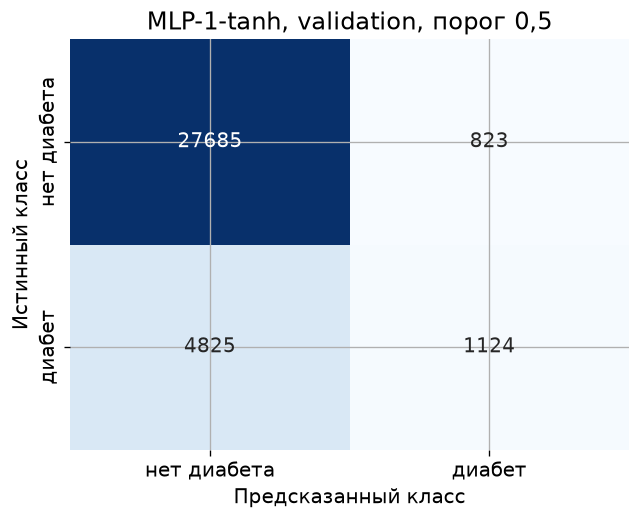

Пропущено больных (FN): 4825 из 5949
Ложных тревог (FP): 823 из 28508


In [25]:
base_probability = trained_models[current_name].predict(X_val, batch_size=8192, verbose=0).ravel()
before_matrix = plot_confusion(y_val, base_probability, 0.5,
                               f"{current_name}, validation, порог 0,5", "binary-confusion-before.png")
print("Пропущено больных (FN):", before_matrix[1, 0], "из", before_matrix[1].sum())
print("Ложных тревог (FP):", before_matrix[0, 1], "из", before_matrix[0].sum())

Веса классов: {0: 0.6043310933718186, 1: 2.8962175792507203}


MLP-1-tanh-cw: эпох 19, лучшая 13, 70 с, {'Recall': 0.7527, 'Precision': 0.3515, 'Balanced Accuracy': 0.7315, 'ROC-AUC': 0.8063}


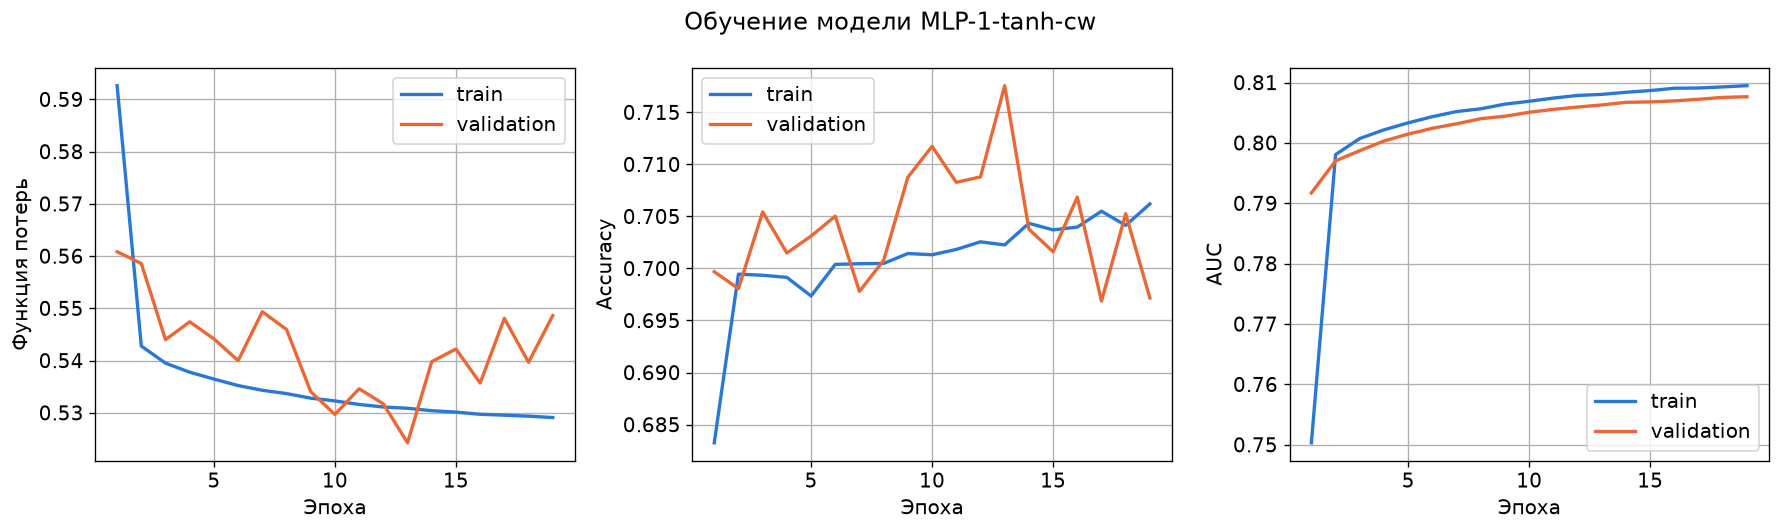

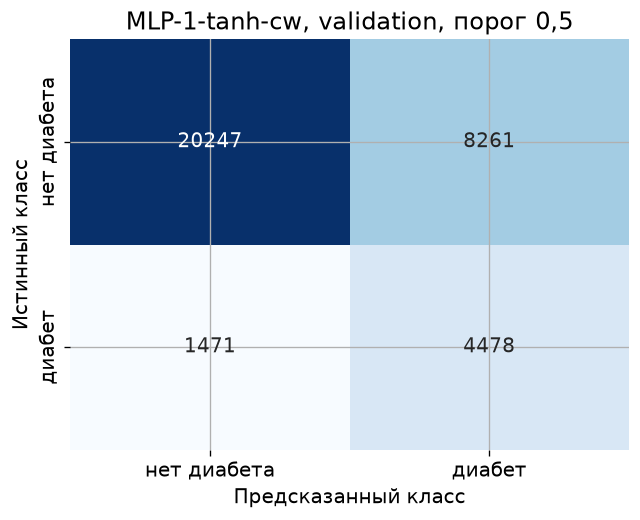

Пропущено больных (FN): 1471 из 5949
Ложных тревог (FP): 8261 из 28508


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,class_weight,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,Recall,Precision,Balanced Accuracy,ROC-AUC
0,MLP-1-tanh,16,tanh,adam,0.001,1024,0.0,0.0,нет,369,57,51,210.4,0.3650,0.3666,0.1889,0.5773,0.5800,0.8092
1,MLP-1-tanh-cw,16,tanh,adam,0.001,1024,0.0,0.0,да,369,19,13,70.3,0.5309,0.5242,0.7527,0.3515,0.7315,0.8063


In [26]:
# Веса "balanced": вес класса обратно пропорционален его доле в обучающей части
class_weights = compute_class_weight("balanced", classes=np.array([0.0, 1.0]), y=y_train)
class_weight_dict = {0: float(class_weights[0]), 1: float(class_weights[1])}
print("Веса классов:", class_weight_dict)

weighted_name = f"{current_name}-cw"
run_experiment(weighted_name, **{**current_config, "class_weight": class_weight_dict})
plot_history(weighted_name, "binary-class-weight-history.png")

weighted_probability = trained_models[weighted_name].predict(X_val, batch_size=8192, verbose=0).ravel()
weighted_matrix = plot_confusion(y_val, weighted_probability, 0.5,
                                 f"{weighted_name}, validation, порог 0,5", "binary-confusion-after.png")
print("Пропущено больных (FN):", weighted_matrix[1, 0], "из", weighted_matrix[1].sum())
print("Ложных тревог (FP):", weighted_matrix[0, 1], "из", weighted_matrix[0].sum())
experiments_table([current_name, weighted_name])

**Результат:** матрица ошибок показывает главную проблему: при пороге 0,5 модель MLP-1-tanh пропускает 4825 из 5949 больных (81%), ложных тревог всего 823. Классы путаются в одну сторону: сеть почти всегда выбирает частый класс 0, потому что при доле больных 0,17 это выгодно для функции потерь.

С весами классов (0,6043 и 2,8962) пропущено 1471 больной вместо 4825, Recall вырос с 0,1889 до 0,7527, Balanced Accuracy с 0,58 до 0,7315. Цена этого: ложных тревог 8261 вместо 823, Precision упала с 0,5773 до 0,3515. ROC-AUC почти не изменился (0,8063 против 0,8092). Это значит, что веса не улучшили разделение классов, а только сдвинули границу решения. Такой же сдвиг можно получить порогом, не обучая сеть заново.

### 9. Выбор порога на validation

Порог 0,5 при дисбалансе не обязан быть лучшим. Для итоговой модели перебираем порог на validation и смотрим компромисс Recall и Precision. Итоговая модель - лучшая по ROC-AUC среди всех моделей, обученных с ранней остановкой (при равенстве более простая и стоящая раньше в таблице).

Проверяем три правила: максимум Balanced Accuracy, максимум F1 и порог, при котором Precision достигает ориентира 0,80.

Итоговая модель: MLP-1-tanh


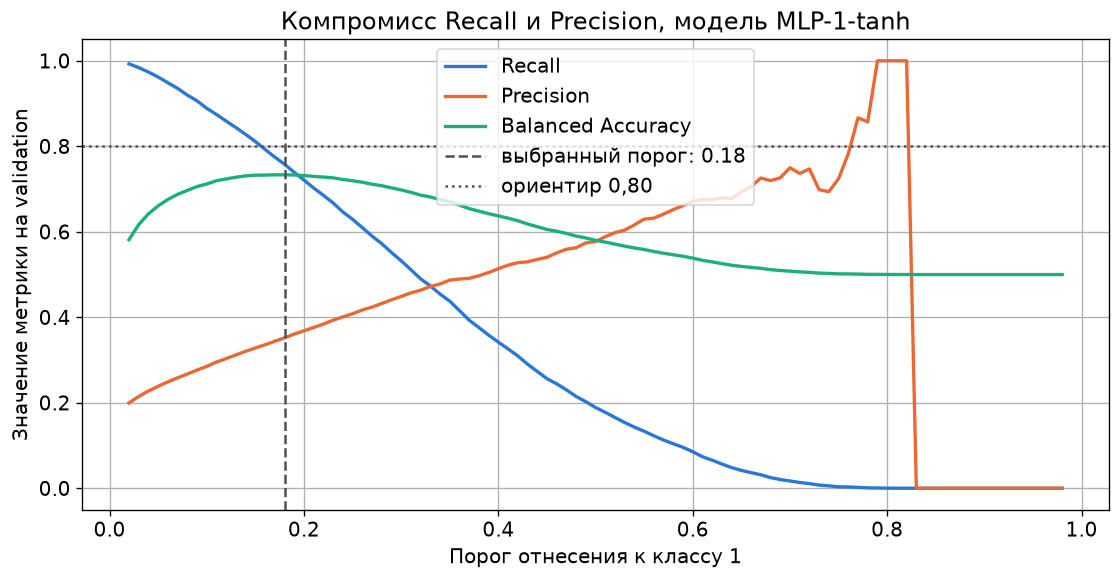

Максимальная Precision на сетке порогов: 1.0


,Правило,Порог,Recall,Precision,Balanced Accuracy,ROC-AUC
0,"Порог 0,5",0.50,0.1889,0.5773,0.5800,0.8092
1,Максимум Balanced Accuracy,0.18,0.7581,0.3518,0.7333,0.8092
2,Максимум F1,0.26,0.6099,0.4171,0.7160,0.8092
3,"Precision не ниже 0,80",0.77,0.0022,0.8667,0.5011,0.8092


In [27]:
# Модели без ранней остановки были нужны только для показа переобучения, в выбор они не входят
selectable_names = [row["Модель"] for row in experiment_rows if "no-es" not in row["Модель"]]
final_name = select_simplest_best(selectable_names)
final_model = trained_models[final_name]
print("Итоговая модель:", final_name)

final_val_probability = final_model.predict(X_val, batch_size=8192, verbose=0).ravel()

# Для каждого порога считаем метрики на validation
threshold_grid = np.round(np.arange(0.02, 0.99, 0.01), 2)
threshold_rows = []
for threshold in threshold_grid:
    predicted_labels = (final_val_probability >= threshold).astype(int)
    threshold_rows.append({
        "Порог": threshold,
        "Recall": recall_score(y_val, predicted_labels, zero_division=0),
        "Precision": precision_score(y_val, predicted_labels, zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_val, predicted_labels),
        "F1": f1_score(y_val, predicted_labels, zero_division=0),
    })
threshold_table = pd.DataFrame(threshold_rows)

best_balanced_threshold = threshold_table.loc[threshold_table["Balanced Accuracy"].idxmax(), "Порог"]
best_f1_threshold = threshold_table.loc[threshold_table["F1"].idxmax(), "Порог"]

figure, axis = plt.subplots(figsize=(9.5, 5))
axis.plot(threshold_table["Порог"], threshold_table["Recall"], color="#2a78d6", linewidth=2, label="Recall")
axis.plot(threshold_table["Порог"], threshold_table["Precision"], color="#eb6834", linewidth=2, label="Precision")
axis.plot(threshold_table["Порог"], threshold_table["Balanced Accuracy"], color="#1baf7a", linewidth=2, label="Balanced Accuracy")
axis.axvline(best_balanced_threshold, color=TEST_COLOR, linestyle="--", linewidth=1.5,
             label=f"выбранный порог: {best_balanced_threshold:.2f}")
axis.axhline(0.8, color=TEST_COLOR, linestyle=":", linewidth=1.5, label="ориентир 0,80")
axis.set_xlabel("Порог отнесения к классу 1")
axis.set_ylabel("Значение метрики на validation")
axis.set_title(f"Компромисс Recall и Precision, модель {final_name}")
axis.legend()
figure.tight_layout()
figure.savefig(FIGURES_DIR / "binary-threshold.png")
plt.show()

# Сводка по правилам выбора порога
rule_rows = []
for rule_name, threshold in [("Порог 0,5", 0.5), ("Максимум Balanced Accuracy", best_balanced_threshold),
                             ("Максимум F1", best_f1_threshold)]:
    rule_rows.append({"Правило": rule_name, "Порог": threshold, **evaluate_binary(y_val, final_val_probability, threshold)})

# Самый низкий порог, при котором Precision на validation не ниже 0,80, если такой есть
precise_thresholds = threshold_table[threshold_table["Precision"] >= 0.8]
if len(precise_thresholds) > 0:
    precise_threshold = precise_thresholds["Порог"].min()
    rule_rows.append({"Правило": "Precision не ниже 0,80", "Порог": precise_threshold,
                      **evaluate_binary(y_val, final_val_probability, precise_threshold)})
else:
    print("Ни при одном пороге из сетки Precision на validation не достигает 0,80")

print("Максимальная Precision на сетке порогов:", round(threshold_table["Precision"].max(), 4))
threshold_rules = pd.DataFrame(rule_rows)
threshold_rules.to_csv(RESULTS_DIR / "binary-threshold-rules.csv", index=False, encoding="utf-8")
threshold_rules

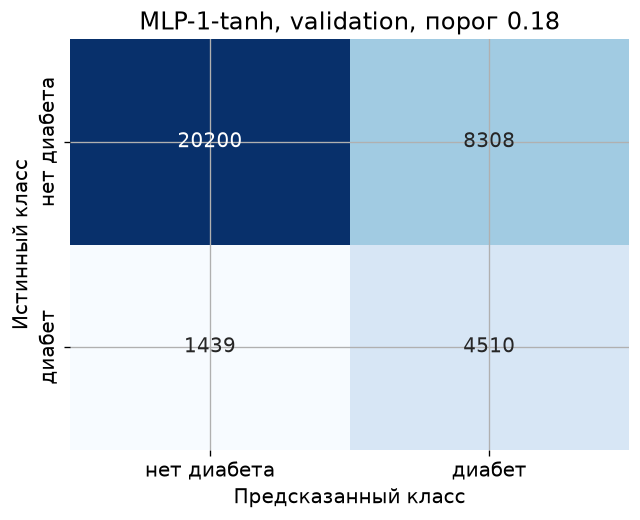

Пропущено больных (FN): 1439 из 5949
Ложных тревог (FP): 8308 из 28508


In [28]:
# Итоговый порог: максимум Balanced Accuracy. При скрининге пропуск больного дороже ложной
# тревоги, а Balanced Accuracy одинаково учитывает полноту обоих классов
final_threshold = float(best_balanced_threshold)

after_threshold_matrix = plot_confusion(
    y_val, final_val_probability, final_threshold,
    f"{final_name}, validation, порог {final_threshold:.2f}", "binary-confusion-threshold.png")
print("Пропущено больных (FN):", after_threshold_matrix[1, 0], "из", after_threshold_matrix[1].sum())
print("Ложных тревог (FP):", after_threshold_matrix[0, 1], "из", after_threshold_matrix[0].sum())

**Результат:** итоговая модель MLP-1-tanh. Максимум Balanced Accuracy на validation достигается при пороге 0,18: Recall 0,7581, Precision 0,3518, Balanced Accuracy 0,7333. При максимуме F1 (порог 0,26) Recall 0,6099, Precision 0,4171. Выбран порог 0,18: при скрининге пропуск больного дороже ложной тревоги. Пропущено 1439 больных вместо 4825 при пороге 0,5, ложных тревог 8308. Результат совпадает с `class_weight` (1471 и 8261), что подтверждает: это один и тот же сдвиг границы.

Precision 0,80 достигается только при пороге 0,77, но тогда Recall равен 0,0022: модель находит единицы больных. Значения Precision около 1 при порогах выше 0,78 получены на единичных объектах, поэтому смысла не имеют, а выше 0,82 модель не называет больным никого. Поэтому одновременно получить Recall и Precision 0,80 на этих данных нельзя.

### 10. Сводная таблица экспериментов

Все исследованные модели с параметрами и метриками на validation (порог 0,5). Таблица сохраняется в `results/binary-experiments.csv`.

In [29]:
all_experiments = experiments_table()
all_experiments.to_csv(RESULTS_DIR / "binary-experiments.csv", index=False, encoding="utf-8")

# Истории обучения трех основных архитектур и итоговой модели сохраняем для отчета
for file_suffix, model_name in [("mlp-1", "MLP-1"), ("mlp-2", "MLP-2"), ("mlp-3", "MLP-3"), ("best", final_name)]:
    pd.DataFrame(trained_histories[model_name]).round(4).to_csv(
        RESULTS_DIR / f"binary-history-{file_suffix}.csv", index_label="epoch", encoding="utf-8")

pd.set_option("display.max_columns", None, "display.width", 250)
all_experiments

,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,class_weight,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,Recall,Precision,Balanced Accuracy,ROC-AUC
0,MLP-1,16,relu,adam,0.0010,1024,0.0,0.0000,нет,369,57,51,194.7,0.3650,0.3670,0.1933,0.5699,0.5814,0.8084
1,MLP-2,64-32,relu,adam,0.0010,1024,0.0,0.0000,нет,3521,19,13,78.4,0.3642,0.3668,0.2128,0.5721,0.5898,0.8088
2,MLP-3,256-128-64,relu,adam,0.0010,1024,0.0,0.0000,нет,46849,16,10,66.3,0.3621,0.3675,0.1726,0.5971,0.5742,0.8080
3,MLP-1-tanh,16,tanh,adam,0.0010,1024,0.0,0.0000,нет,369,57,51,210.4,0.3650,0.3666,0.1889,0.5773,0.5800,0.8092
4,MLP-1-tanh-rmsprop,16,tanh,rmsprop,0.0010,1024,0.0,0.0000,нет,369,40,34,135.7,0.3655,0.3670,0.1876,0.5828,0.5798,0.8085
5,MLP-1-tanh-sgd,16,tanh,sgd,0.0100,1024,0.0,0.0000,нет,369,60,59,195.2,0.3661,0.3672,0.1874,0.5721,0.5791,0.8081
6,MLP-1-tanh-lr0.01,16,tanh,adam,0.0100,1024,0.0,0.0000,нет,369,14,8,46.9,0.3667,0.3672,0.2239,0.5597,0.5936,0.8086
7,MLP-1-tanh-lr0.0001,16,tanh,adam,0.0001,1024,0.0,0.0000,нет,369,60,60,212.2,0.3703,0.3718,0.1691,0.5752,0.5715,0.8017
8,MLP-1-tanh-batch512,16,tanh,adam,0.0010,512,0.0,0.0000,нет,369,31,25,284.7,0.3656,0.3669,0.1873,0.5790,0.5794,0.8087
9,MLP-1-tanh-batch4096,16,tanh,adam,0.0010,4096,0.0,0.0000,нет,369,60,59,70.1,0.3667,0.3682,0.1908,0.5776,0.5808,0.8068


## Итоговая оценка на тестовой выборке

Выбор модели и порога закончен, все решения приняты по validation. Теперь один раз считаем метрики всех моделей на test как отчет. После этой таблицы модели не меняются.

In [30]:
test_rows = []

# Все исследованные модели при пороге 0,5
for model_name, model in trained_models.items():
    test_probability = model.predict(X_test, batch_size=8192, verbose=0).ravel()
    test_rows.append({"Модель": model_name, "Порог": 0.5, **evaluate_binary(y_test, test_probability),
                      "Примечание": ""})

# Итоговая модель с порогом, выбранным на validation
final_test_probability = final_model.predict(X_test, batch_size=8192, verbose=0).ravel()
test_rows.append({"Модель": final_name, "Порог": final_threshold,
                  **evaluate_binary(y_test, final_test_probability, final_threshold),
                  "Примечание": "итоговая модель"})

# Базовая модель
dummy_test_probability = dummy_model.predict_proba(X_test)[:, 1]
test_rows.append({"Модель": "Dummy", "Порог": 0.5, **evaluate_binary(y_test, dummy_test_probability),
                  "Примечание": "базовая модель"})

test_metrics = pd.DataFrame(test_rows)
test_metrics.to_csv(RESULTS_DIR / "binary-metrics.csv", index=False, encoding="utf-8")
test_metrics

,Модель,Порог,Recall,Precision,Balanced Accuracy,ROC-AUC,Примечание
0,MLP-1,0.50,0.2021,0.6148,0.5878,0.8122,
1,MLP-2,0.50,0.2150,0.5963,0.5923,0.8125,
2,MLP-3,0.50,0.1796,0.6224,0.5784,0.8116,
3,MLP-1-tanh,0.50,0.1952,0.6185,0.5850,0.8127,
4,MLP-1-tanh-rmsprop,0.50,0.1898,0.6143,0.5825,0.8123,
5,MLP-1-tanh-sgd,0.50,0.1935,0.6158,0.5842,0.8112,
6,MLP-1-tanh-lr0.01,0.50,0.2322,0.5924,0.5994,0.8121,
7,MLP-1-tanh-lr0.0001,0.50,0.1713,0.5949,0.5735,0.8056,
8,MLP-1-tanh-batch512,0.50,0.1947,0.6222,0.5850,0.8123,
9,MLP-1-tanh-batch4096,0.50,0.1942,0.6111,0.5842,0.8104,


Кривые итоговой модели с линией итогового значения на test, матрица ошибок и ROC-кривая.

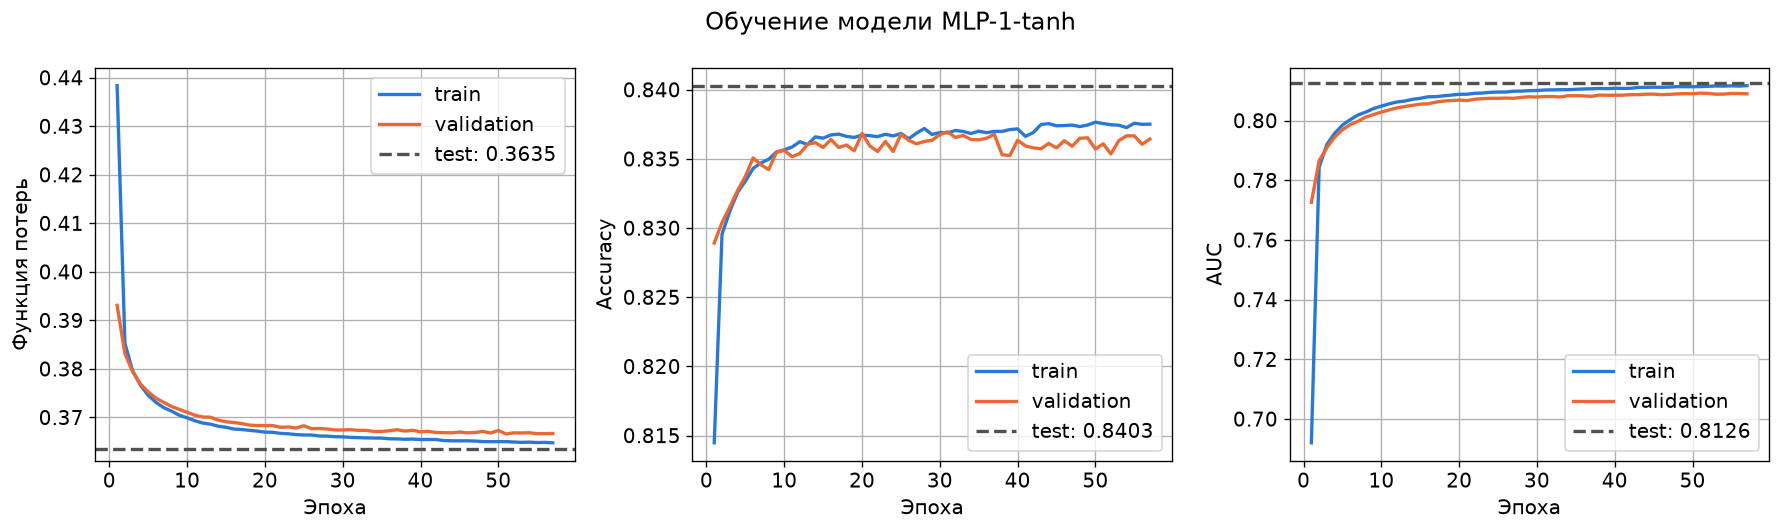

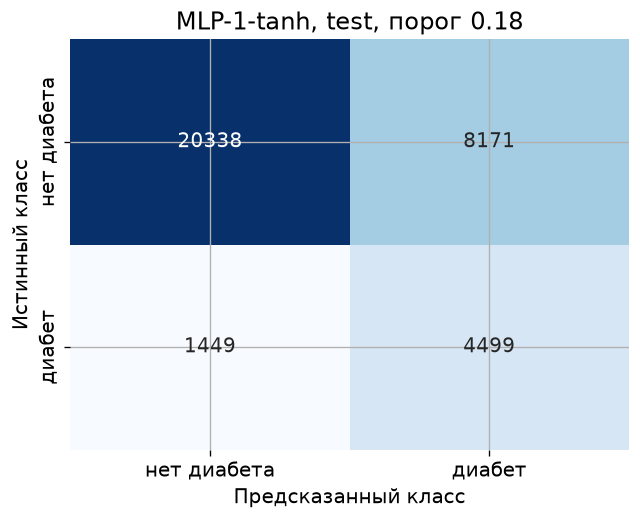

Матрица ошибок на test (строки - истинный класс):
[[20338  8171]
 [ 1449  4499]]


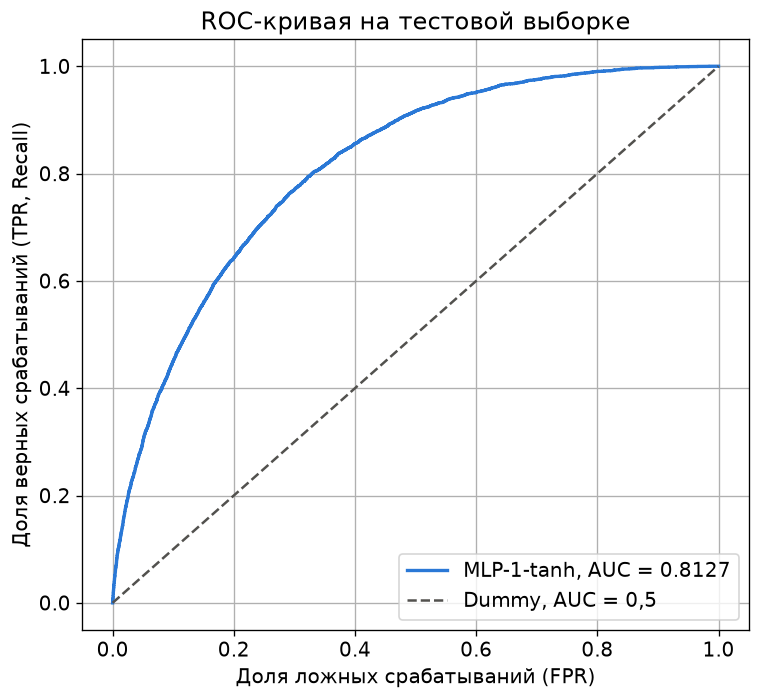

In [31]:
test_loss, test_accuracy, test_auc = final_model.evaluate(X_test, y_test, batch_size=8192, verbose=0)
plot_history(final_name, "binary-best-history.png",
             test_values={"loss": test_loss, "accuracy": test_accuracy, "auc": test_auc})

test_matrix = plot_confusion(y_test, final_test_probability, final_threshold,
                             f"{final_name}, test, порог {final_threshold:.2f}", "binary-confusion-test.png")
print("Матрица ошибок на test (строки - истинный класс):")
print(test_matrix)
pd.DataFrame(test_matrix, index=["истинный 0", "истинный 1"], columns=["предсказан 0", "предсказан 1"]).to_csv(
    RESULTS_DIR / "binary-confusion-test.csv", encoding="utf-8")

false_positive_rate, true_positive_rate, _ = roc_curve(y_test, final_test_probability)
test_roc_auc = roc_auc_score(y_test, final_test_probability)
figure, axis = plt.subplots(figsize=(6.5, 6))
axis.plot(false_positive_rate, true_positive_rate, color=TRAIN_COLOR, linewidth=2,
          label=f"{final_name}, AUC = {test_roc_auc:.4f}")
axis.plot([0, 1], [0, 1], color=TEST_COLOR, linestyle="--", linewidth=1.5, label="Dummy, AUC = 0,5")
axis.set_xlabel("Доля ложных срабатываний (FPR)")
axis.set_ylabel("Доля верных срабатываний (TPR, Recall)")
axis.set_title("ROC-кривая на тестовой выборке")
axis.legend(loc="lower right")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "binary-roc.png")
plt.show()

In [32]:
# Сохраняем основные архитектуры и итоговую модель. Лабораторная работа 5 загружает
# binary-best.keras и binary-preprocessor.joblib, а не обучает модель заново
for model_name in ["MLP-1", "MLP-2", "MLP-3"]:
    trained_models[model_name].save(MODELS_DIR / f"binary-{model_name.lower()}.keras")
final_model.save(MODELS_DIR / "binary-best.keras")

# Настройки итоговой модели, без которых ее предсказания не воспроизвести
final_info = {
    "model": final_name,
    "threshold": final_threshold,
    "bmi_upper_bound": bmi_upper_bound,
    "config": {key: value for key, value in model_configs[final_name].items()},
}
with open(MODELS_DIR / "binary-best-info.json", "w", encoding="utf-8") as info_file:
    json.dump(final_info, info_file, ensure_ascii=False, indent=2)
print(json.dumps(final_info, ensure_ascii=False, indent=2))

{
  "model": "MLP-1-tanh",
  "threshold": 0.18,
  "bmi_upper_bound": 81.0,
  "config": {
    "hidden_units": [
      16
    ],
    "activation": "tanh",
    "optimizer_name": "adam",
    "learning_rate": 0.001,
    "batch_size": 1024,
    "dropout_rate": 0.0,
    "l2_factor": 0.0,
    "class_weight": null
  }
}


**Результат:** на test итоговая модель MLP-1-tanh с порогом 0,18 дала Recall 0,7564, Precision 0,3551, Balanced Accuracy 0,7349, ROC-AUC 0,8127. Значения близки к validation (0,7581, 0,3518, 0,7333, 0,8092), значит переобучения под validation нет. `Dummy` на test: Recall 0, Precision 0, Balanced Accuracy 0,5, ROC-AUC 0,5.

Матрица ошибок на test: верно найдено 4499 больных из 5948, пропущено 1449, ложных тревог 8171 из 28 509.

Таблица подтверждает выводы экспериментов: все модели с ранней остановкой имеют ROC-AUC от 0,8056 до 0,8130, а большая сеть без ранней остановки и без Dropout только 0,7557. MLP-1-tanh-l2 на test дала 0,8130, что на 0,0003 выше итоговой модели, но выбор сделан по validation и после этой таблицы не меняется.

## Вывод

Построен бинарный классификатор риска диабета по анкете BRFSS 2015. Лучшая модель - MLP-1-tanh: один скрытый слой из 16 нейронов с tanh, Adam, скорость обучения 0,001, размер пакета 1024, порог 0,18, выбранный на validation.

| Метрика на test | Итоговая модель | Dummy | Ориентир |
|---|---|---|---|
| Recall | 0,7564 | 0 | 0,80 |
| Precision | 0,3551 | 0 | 0,80 |
| Balanced Accuracy | 0,7349 | 0,5 | 0,80 |
| ROC-AUC | 0,8127 | 0,5 | 0,80 |

**Сравнение с базовой моделью.** Модель намного лучше `Dummy`: она находит три четверти больных, а `Dummy` не находит никого. ROC-AUC превышает ориентир.

**Выбор архитектуры.** Простейшая сеть оказалась лучшей: 369 параметров дают то же качество, что и 46 849. Рост сложности не улучшал ROC-AUC, но приближал переобучение. Поэтому выбрана самая простая модель.

**Переобучение.** У итоговой модели его нет: кривые train и validation идут рядом. Оно появляется только у большой сети без ранней остановки, там Dropout помог. Для итоговой модели Dropout не нужен и даже вреден, поэтому не используется.

**Почему не достигнуты ориентиры Recall, Precision и Balanced Accuracy.** Эксперименты с архитектурой, активацией, оптимизатором, скоростью обучения, весами классов и порогом не сдвинули ROC-AUC выше примерно 0,81. Значит, предел задают данные, а не модель:

1. Анкета описывает риск, а не диагноз: сильнейшая корреляция признака с меткой только 0,301.
2. Метка шумная: диагноз указан со слов респондента, а по описанию набора многие больные не знают о своей болезни. Есть 1804 группы с одинаковыми признаками и разными метками.
3. Положительный класс редкий (0,1726). Даже при хорошем ранжировании среди людей с похожей анкетой здоровых больше, чем больных, поэтому Precision низкая. Так, при Recall 0,76 только 36% срабатываний верны.

**Компромисс Recall и Precision.** Порог задает выбор между пропусками и ложными тревогами. При пороге 0,5 Precision выше (0,5773 на validation), но пропускается 81% больных. При пороге 0,18 пропускается около 24%, но почти две трети срабатываний ложные. Для скрининга, где ложная тревога означает лишь дополнительный анализ крови, выбран низкий порог. Завышать метрики утечкой или изменением тестовой выборки мы не стали.

**Ограничения и возможные улучшения.** Данные относятся к одному году и к жителям США. Качество может улучшить не усложнение сети, а новые признаки: например, результаты анализов крови (глюкоза, гликированный гемоглобин), которых в опросе нет.